# 🌍 EarthScape Climate Agency: Big Data Climate Analytics (Colab + Keras)

**Pipeline:** Ingestion → Cleaning → Partitioned Parquet storage → PySpark (MapReduce-style) → EDA → Feature engineering → Models (baselines, Ridge, RandomForest, GradientBoosting, Keras LSTM, Ensemble) → Evaluation → Anomaly detection → Correlation → Forecast on **unseen new data** → Real-time replay + alerts → Auth/DB/Security/Backup → Dashboard.

> Hadoop/HDFS/MapReduce/Impala are **not used** (hardware + updated requirements). Replacements: **partitioned Parquet** (storage), **PySpark/Pandas** (processing), **Spark SQL / Pandas** (queries).

**Run order:** Runtime → Change runtime type → **T4 GPU**, then *Run all*.

**Golden rule used everywhere:** time-series are split **chronologically** (never shuffled), every feature at month *t* uses data only up to *t-1*, scalers/models are fitted on training data only, and the last 12 months are kept as a completely **unseen "new data" hold-out**.

## 0. Setup

In [1]:
!pip install -q statsmodels pyarrow cryptography psutil plotly pyspark

In [2]:
import os, sys, time, json, pickle, shutil, hashlib, hmac, secrets, sqlite3, warnings, random, functools, zipfile
from datetime import datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import psutil
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED); random.seed(SEED)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 4)
pd.set_option('display.width', 200)

# Google Drive (Colab) or local folder (fallback)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/EarthScape'
except Exception as e:
    BASE = os.path.abspath('./EarthScape')
    print('⚠️ Google Drive NOT mounted (', str(e)[:60], ') → files are saved in', BASE, 'and will be LOST when the session ends.')
    print('   Fix: rerun this cell and click Allow on the Drive popup, or download the backup zip from the last cell.')
for d in ['data/raw', 'data/clean', 'data/parquet', 'data/stream', 'models', 'outputs', 'backups', 'db', 'logs']:
    os.makedirs(f'{BASE}/{d}', exist_ok=True)
print('Working folder:', BASE)

# ---- performance monitoring (requirement: track time + resources) ----
PERF = []
def monitored(fn):
    @functools.wraps(fn)
    def wrapper(*a, **k):
        t0 = time.time()
        r = fn(*a, **k)
        PERF.append(dict(stage=fn.__name__, seconds=round(time.time() - t0, 3),
                         ram_mb=round(psutil.Process().memory_info().rss / 1e6, 1),
                         cpu_pct=psutil.cpu_percent(), at=datetime.now().isoformat(timespec='seconds')))
        return r
    return wrapper

Mounted at /content/drive
Working folder: /content/drive/MyDrive/EarthScape


In [3]:
CONFIG = dict(
    NASA_URL='https://data.giss.nasa.gov/gistemp/tabledata_v4/GLB.Ts+dSST.csv',
    MLO_URL='https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv',
    OWID_URL='https://owid-public.owid.io/data/co2/owid-co2-data.csv',
    OWID_URL_ALT='https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv',   # backup link
    MODEL_START='1958-03-01',     # monthly Mauna Loa CO2 exists from March 1958
    VAL_MONTHS=96, TEST_MONTHS=96, NEW_MONTHS=12,   # chronological splits (+ unseen new-data hold-out)
    WINDOW=24,                    # LSTM looks at the previous 24 months
    HORIZON=12,                   # forecast 12 months ahead
    INTERVAL=0.90,                # 90% prediction interval
    ALERT_THRESHOLD=1.50,         # deg C anomaly that triggers CRITICAL alert (admin-configurable; today's typical anomaly is ~1.2-1.4)
    ANOMALY_Z=3.0,                # anomaly detector sensitivity
)

## 1. Data ingestion (batch / historical)
Three real, free sources: **NASA GISTEMP** (global temperature anomaly, 1880→now), **NOAA Mauna Loa** (monthly atmospheric CO₂, a station + satellite-era instrument record) and **Our World in Data** (annual greenhouse-gas emissions).
If a download fails, upload the CSV manually into `data/raw/` and put its path in `CONFIG`.

In [4]:
def read_with_retry(fn, tries=3):
    for i in range(tries):
        try:
            return fn()
        except Exception as e:
            print(f'  retry {i+1}/{tries}: {e}'); time.sleep(2)
    raise RuntimeError('Download failed. Upload the CSV into data/raw and set its path in CONFIG.')

def read_any(urls):
    last = None
    for u in urls:
        try: return pd.read_csv(u)
        except Exception as e: last = e
    raise last

@monitored
def ingest():
    nasa = read_with_retry(lambda: pd.read_csv(CONFIG['NASA_URL'], skiprows=1, na_values=['***', '****']))
    mlo  = read_with_retry(lambda: pd.read_csv(CONFIG['MLO_URL'], comment='#'))
    owid = read_with_retry(lambda: read_any([CONFIG['OWID_URL'], CONFIG['OWID_URL_ALT']]))
    return nasa, mlo, owid

nasa_raw, mlo_raw, owid_raw = ingest()
nasa_raw.to_csv(f'{BASE}/data/raw/nasa_gistemp.csv', index=False)
mlo_raw.to_csv(f'{BASE}/data/raw/noaa_mlo_co2.csv', index=False)
owid_raw.to_csv(f'{BASE}/data/raw/owid_co2.csv', index=False)
print(nasa_raw.shape, mlo_raw.shape, owid_raw.shape)
nasa_raw.tail(3)

(147, 19) (823, 8) (56269, 79)


,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,J-D,D-N,DJF,MAM,JJA,SON
144,2024,1.25,1.43,1.39,1.32,1.16,1.23,1.20,1.30,1.21,1.34,1.29,1.26,1.28,1.29,1.35,1.29,1.25,1.28
145,2025,1.37,1.25,1.36,1.24,1.07,1.06,1.02,1.17,1.24,1.19,1.21,1.05,1.19,1.20,1.30,1.23,1.08,1.21
146,2026,1.08,1.23,1.30,1.16,1.13,1.18,1.24,1.42,1.39,1.55,NaN,NaN,NaN,NaN,1.12,1.20,1.28,NaN


## 2. Data quality audit (before touching anything)

In [5]:
for name, d in [('NASA temperature', nasa_raw), ('Mauna Loa CO2', mlo_raw), ('OWID emissions', owid_raw)]:
    print(f'\n=== {name}: shape={d.shape} ===')
    print('duplicated rows:', int(d.duplicated().sum()))
    miss = d.isna().sum()
    print('columns with missing values (top 8):'); print(miss[miss > 0].sort_values(ascending=False).head(8).to_string() or 'none')
print('\nNASA raw dtypes (should be numeric except where "***" placeholders exist):')
print(nasa_raw.dtypes.head(14).to_string())


=== NASA temperature: shape=(147, 19) ===
duplicated rows: 0
columns with missing values (top 8):
D-N    2
Nov    1
Dec    1
J-D    1
DJF    1
SON    1

=== Mauna Loa CO2: shape=(823, 8) ===
duplicated rows: 0
columns with missing values (top 8):
Series([], )

=== OWID emissions: shape=(56269, 79) ===
duplicated rows: 0
columns with missing values (top 8):
share_global_cumulative_other_co2    54037
share_global_other_co2               54037
other_co2_per_capita                 53418
cumulative_other_co2                 52821
other_industry_co2                   52821
consumption_co2_per_gdp              51821
consumption_co2_per_capita           51489
trade_co2                            51418

NASA raw dtypes (should be numeric except where "***" placeholders exist):
Year      int64
Jan     float64
Feb     float64
Mar     float64
Apr     float64
May     float64
Jun     float64
Jul     float64
Aug     float64
Sep     float64
Oct     float64
Nov     float64
Dec     float64
J-D     floa

## 3. Data cleaning
What is done and **why**:
1. Wide → long (one row per month) and a continuous monthly index.
2. NASA's not-yet-published months (`***`) are dropped from the tail; short gaps (≤3 months) are **linearly interpolated**.
3. Physically implausible values (|anomaly| > 6 °C) are set to missing.
4. Mauna Loa's missing code (`-99.99`) → NaN → interpolated (≤6 months).
5. Outliers are **flagged, not deleted** (real climate extremes are real data).
6. OWID: keep the `World` row, interpolate short gaps.

In [6]:
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

@monitored
def clean_all(nasa, mlo, owid):
    rep = {}
    # ---- temperature ----
    t = nasa[['Year'] + MONTHS].copy()
    t['Year'] = pd.to_numeric(t['Year'], errors='coerce'); t = t.dropna(subset=['Year'])
    t = t.melt(id_vars='Year', var_name='mon', value_name='temp_anomaly')
    t['temp_anomaly'] = pd.to_numeric(t['temp_anomaly'], errors='coerce')
    t['month'] = t['mon'].map({m: i + 1 for i, m in enumerate(MONTHS)})
    t['date'] = pd.to_datetime(dict(year=t.Year.astype(int), month=t.month, day=1))
    t = t.drop_duplicates('date').set_index('date').sort_index()[['temp_anomaly']]
    t = t.loc[:t.temp_anomaly.last_valid_index()]              # drop months not yet published
    t = t.asfreq('MS')
    rep['temp_missing_before'] = int(t.temp_anomaly.isna().sum())
    t['temp_anomaly'] = t.temp_anomaly.interpolate(limit=3, limit_direction='both')
    rep['temp_missing_after'] = int(t.temp_anomaly.isna().sum())
    bad = t.temp_anomaly.abs() > 6
    rep['implausible_removed'] = int(bad.sum()); t.loc[bad, 'temp_anomaly'] = np.nan
    # ---- CO2 monthly ----
    m = mlo.copy(); m.columns = [c.strip().lower().replace(' ', '_') for c in m.columns]
    assert {'year', 'month', 'average', 'deseasonalized'} <= set(m.columns), f'Unexpected MLO columns: {list(m.columns)}'
    m['date'] = pd.to_datetime(dict(year=m['year'].astype(int), month=m['month'].astype(int), day=1))
    m = m.set_index('date').sort_index()
    for c in ['average', 'deseasonalized']:
        m[c] = pd.to_numeric(m[c], errors='coerce').where(lambda s: s > 0)     # -99.99 = missing
    m = m[['average', 'deseasonalized']].rename(columns={'average': 'co2_ppm', 'deseasonalized': 'co2_trend'})
    m = m.asfreq('MS').interpolate(limit=6)
    out = t.join(m, how='left')
    # ---- outlier flagging (flag only) ----
    med = out.temp_anomaly.rolling(120, center=True, min_periods=30).median()
    mad = (out.temp_anomaly - med).abs().rolling(120, center=True, min_periods=30).median() * 1.4826
    out['suspect'] = ((out.temp_anomaly - med).abs() / mad > 4).fillna(False)
    rep['suspect_flagged'] = int(out.suspect.sum())
    # ---- annual greenhouse gases ----
    w = owid[owid['country'] == 'World'].set_index('year')
    keep = [c for c in ['co2', 'methane', 'nitrous_oxide', 'total_ghg', 'population'] if c in w.columns]
    ann = w[keep].rename(columns={'co2': 'co2_emissions'}).sort_index().interpolate(limit=3).dropna(how='all')
    return out, ann, rep

monthly, annual_ghg, clean_report = clean_all(nasa_raw, mlo_raw, owid_raw)
print('Cleaning report:', clean_report)
print('Monthly range:', monthly.index.min().date(), '→', monthly.index.max().date(), '| rows:', len(monthly))
print('Remaining missing values:\n', monthly.isna().sum().to_string())
monthly.tail()

Cleaning report: {'temp_missing_before': 0, 'temp_missing_after': 0, 'implausible_removed': 0, 'suspect_flagged': 3}
Monthly range: 1880-01-01 → 2026-10-01 | rows: 1762
Remaining missing values:
 temp_anomaly      0
co2_ppm         939
co2_trend       939
suspect           0


,temp_anomaly,co2_ppm,co2_trend,suspect
date,,,,
2026-06-01,1.18,431.43,429.00,False
2026-07-01,1.24,429.13,428.74,False
2026-08-01,1.42,427.55,429.48,False
2026-09-01,1.39,426.07,429.55,False
2026-10-01,1.55,NaN,NaN,False


## 4. Storage: partitioned Parquet (replaces HDFS)
Partitioning by `year` gives the same benefit as HDFS partitions: a query for recent years only reads those folders ("partition pruning").

In [7]:
pq_dir = f'{BASE}/data/parquet/monthly'
shutil.rmtree(pq_dir, ignore_errors=True)               # avoid duplicate files on re-run
monthly.to_csv(f'{BASE}/data/clean/monthly_clean.csv')
annual_ghg.to_csv(f'{BASE}/data/clean/annual_ghg.csv')
(monthly.reset_index().assign(year=lambda d: d['date'].dt.year, date=lambda d: d['date'].astype('datetime64[us]'))   # us timestamps: readable by Spark
        .to_parquet(pq_dir, partition_cols=['year'], index=False))
print('Partitions:', len(os.listdir(pq_dir)), '| e.g.', sorted(os.listdir(pq_dir))[:3])
recent = pd.read_parquet(pq_dir, filters=[('year', '>=', 2020)])      # reads only year>=2020 folders
print('Partition-pruned read (year>=2020):', recent.shape)

Partitions: 147 | e.g. ['year=1880', 'year=1881', 'year=1882']
Partition-pruned read (year>=2020): (82, 6)


## 5. Distributed-style processing: PySpark (MapReduce logic) + SQL
`map` → emit `(decade, (temp, 1))`, `reduceByKey` → sum and count, then average. This is exactly the MapReduce pattern, running on Spark locally. If Spark is unavailable the same result is produced with Pandas.

In [8]:
@monitored
def mapreduce_decades():
    try:
        from pyspark.sql import SparkSession
        spark = SparkSession.builder.master('local[*]').appName('EarthScape').getOrCreate()
        spark.sparkContext.setLogLevel('ERROR')
        sdf = spark.read.parquet(pq_dir)
        rdd = sdf.select('year', 'temp_anomaly').rdd.filter(lambda r: r.temp_anomaly is not None)
        res = (rdd.map(lambda r: ((r.year // 10) * 10, (r.temp_anomaly, 1)))              # MAP
                  .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))                  # REDUCE
                  .mapValues(lambda v: round(v[0] / v[1], 3)).sortByKey().collect())
        sdf.createOrReplaceTempView('monthly')                                           # SQL (Impala replacement)
        print('Spark SQL: 5 warmest years')
        spark.sql('SELECT year, ROUND(AVG(temp_anomaly),3) AS avg_anomaly FROM monthly GROUP BY year ORDER BY avg_anomaly DESC LIMIT 5').show()
        return pd.Series(dict(res)), 'PySpark MapReduce'
    except Exception as e:
        print('PySpark unavailable → Pandas fallback:', str(e)[:80])
        s = monthly.temp_anomaly.groupby((monthly.index.year // 10) * 10).mean().round(3).rename_axis('decade')
        return s, 'Pandas fallback'

decade_avg, engine = mapreduce_decades()
print('Engine:', engine); decade_avg

Spark SQL: 5 warmest years
+----+-----------+
|year|avg_anomaly|
+----+-----------+
|2024|      1.282|
|2026|      1.268|
|2025|      1.186|
|2023|      1.169|
|2016|      1.011|
+----+-----------+

Engine: PySpark MapReduce


,0
1880,-0.213
1890,-0.237
1900,-0.312
1910,-0.328
1920,-0.240
1930,-0.123
1940,0.044
1950,-0.048
1960,-0.030
1970,0.035


## 6. Exploratory Data Analysis (EDA)

In [9]:
display(monthly[['temp_anomaly', 'co2_ppm', 'co2_trend']].describe().T)
print('Missing:', monthly[['temp_anomaly', 'co2_trend']].isna().sum().to_dict())

,count,mean,std,min,25%,50%,75%,max
temp_anomaly,1762.0,0.089637,0.421454,-0.81,-0.220,-0.03,0.320,1.55
co2_ppm,823.0,361.439101,33.511832,312.42,331.285,356.38,387.845,432.34
co2_trend,823.0,361.431786,33.451725,314.44,330.915,356.50,387.825,429.55


Missing: {'temp_anomaly': 0, 'co2_trend': 939}


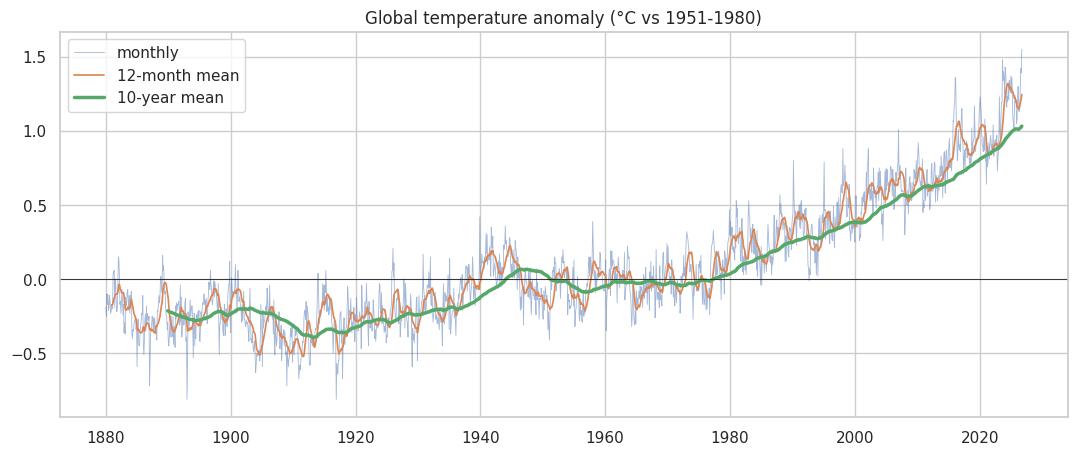

Warming rate 1880-1950: +0.035 °C per decade
Warming rate 1951-2000: +0.113 °C per decade
Warming rate 2001-2026: +0.270 °C per decade


In [10]:
# 6.1 Long-term trend
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly.index, monthly.temp_anomaly, lw=.6, alpha=.5, label='monthly')
ax.plot(monthly.index, monthly.temp_anomaly.rolling(12).mean(), lw=1.2, label='12-month mean')
ax.plot(monthly.index, monthly.temp_anomaly.rolling(120).mean(), lw=2.5, label='10-year mean')
ax.axhline(0, color='k', lw=.6); ax.set_title('Global temperature anomaly (°C vs 1951-1980)'); ax.legend(); plt.show()

yr = monthly.temp_anomaly.groupby(monthly.index.year).mean()
for a, b in [(1880, 1950), (1951, 2000), (2001, int(yr.index.max()))]:
    sl = np.polyfit(yr.loc[a:b].index, yr.loc[a:b].values, 1)[0] * 10
    print(f'Warming rate {a}-{b}: {sl:+.3f} °C per decade')

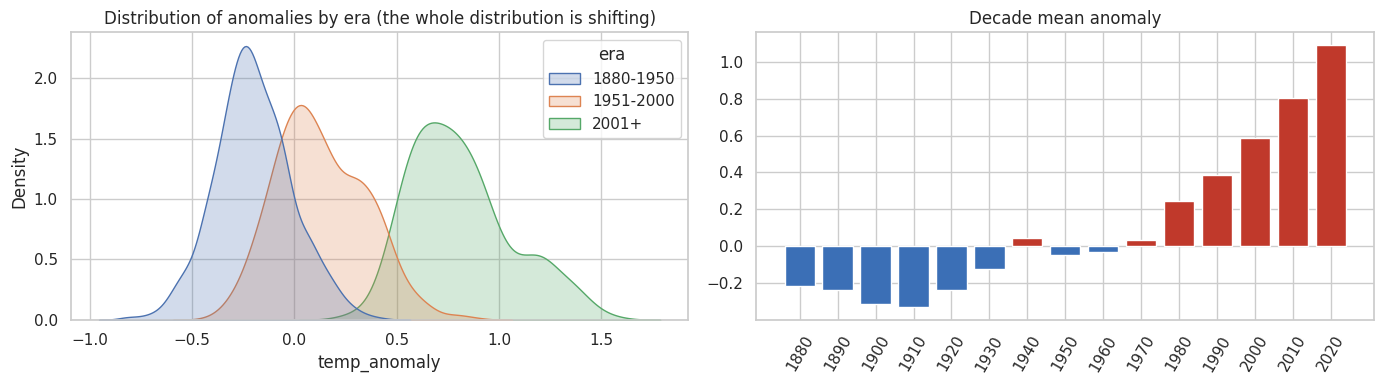

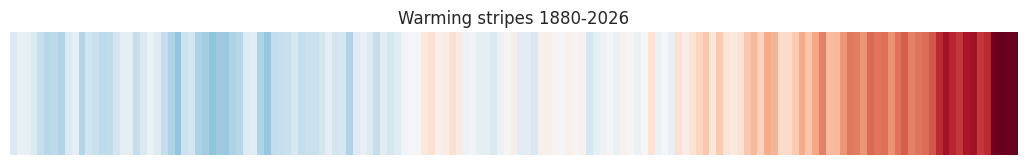

In [11]:
# 6.2 Distribution shift across eras + decade averages
era = pd.cut(monthly.index.year, [1879, 1950, 2000, 2100], labels=['1880-1950', '1951-2000', '2001+'])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.kdeplot(data=monthly.assign(era=era), x='temp_anomaly', hue='era', fill=True, common_norm=False, ax=ax[0])
ax[0].set_title('Distribution of anomalies by era (the whole distribution is shifting)')
dec = monthly.temp_anomaly.groupby((monthly.index.year // 10) * 10).mean()
ax[1].bar(dec.index.astype(str), dec.values, color=['#3b6fb6' if v < 0 else '#c0392b' for v in dec.values])
ax[1].set_title('Decade mean anomaly'); ax[1].tick_params(axis='x', rotation=60); plt.tight_layout(); plt.show()

# warming stripes
fig, ax = plt.subplots(figsize=(13, 1.6))
ax.imshow(yr.values[None, :], aspect='auto', cmap='RdBu_r', vmin=-1.2, vmax=1.2); ax.axis('off')
ax.set_title(f'Warming stripes {int(yr.index.min())}-{int(yr.index.max())}'); plt.show()

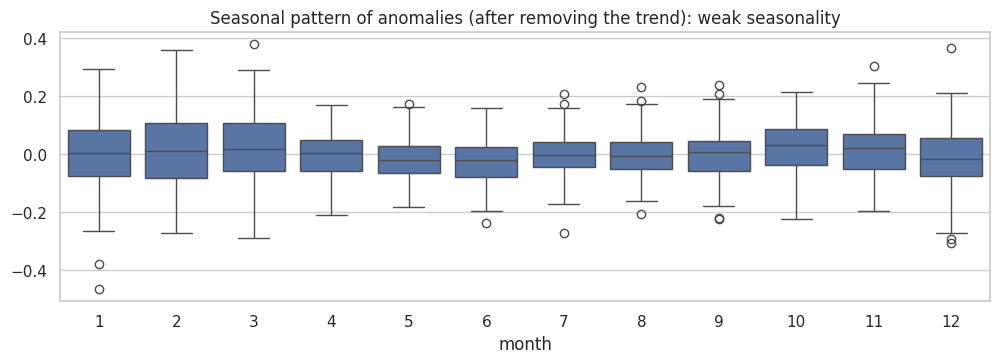

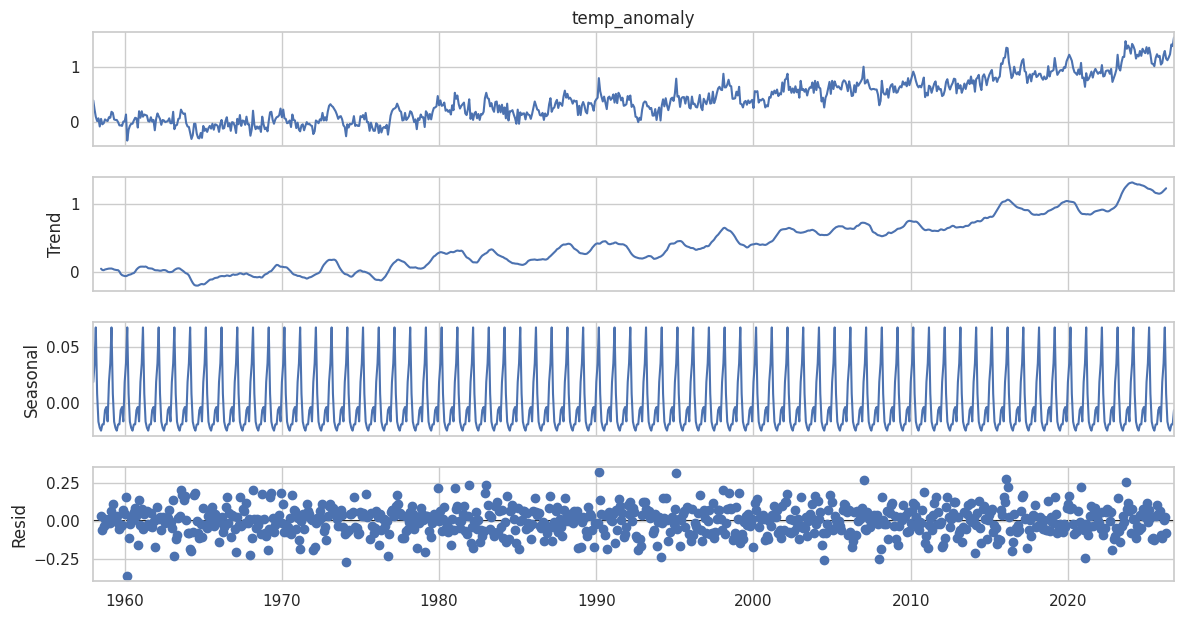

ADF test on level            : p-value=0.9779 → NON-stationary (has trend)
ADF test on first difference : p-value=0.0000 → stationary
→ The level has a trend, so models predict the DEVIATION from the recent 12-month level (stationary), not the raw level.


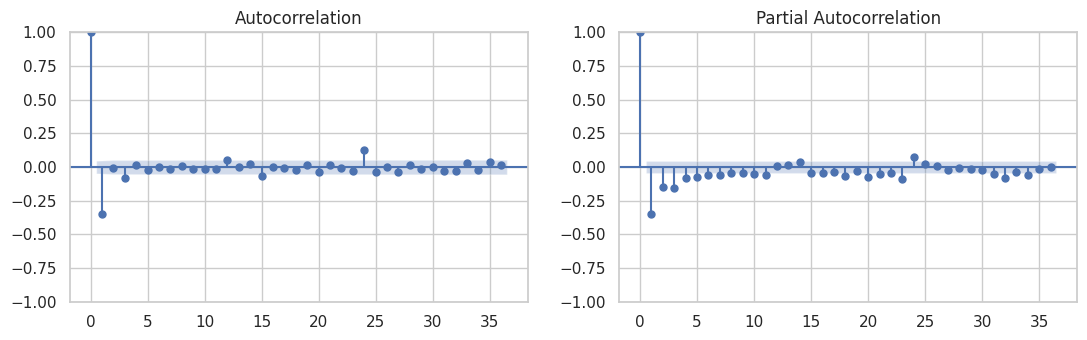

In [12]:
# 6.3 Seasonality + decomposition + stationarity
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

seas = monthly.temp_anomaly - monthly.temp_anomaly.rolling(12, center=True).mean()
fig, ax = plt.subplots(figsize=(12, 3.5)); sns.boxplot(x=seas.index.month, y=seas.values, ax=ax)
ax.set_title('Seasonal pattern of anomalies (after removing the trend): weak seasonality'); ax.set_xlabel('month'); plt.show()

dec_res = seasonal_decompose(monthly.temp_anomaly.loc['1958':].dropna(), model='additive', period=12)
dec_res.plot().set_size_inches(12, 7); plt.show()

y_ = monthly.temp_anomaly.dropna()
for name, s in [('level', y_), ('first difference', y_.diff().dropna())]:
    stat, p = adfuller(s)[:2]
    print(f'ADF test on {name:17s}: p-value={p:.4f} → {"stationary" if p < 0.05 else "NON-stationary (has trend)"}')
print('→ The level has a trend, so models predict the DEVIATION from the recent 12-month level (stationary), not the raw level.')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
plot_acf(y_.diff().dropna(), lags=36, ax=ax[0]); plot_pacf(y_.diff().dropna(), lags=36, ax=ax[1], method='ywm'); plt.show()

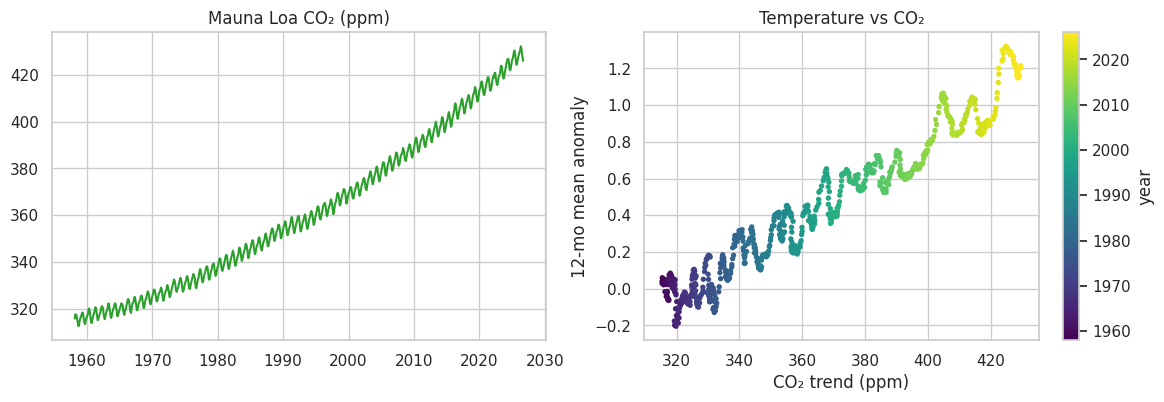

In [13]:
# 6.4 CO2 vs temperature
d = monthly.loc['1958':]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(d.index, d.co2_ppm, color='tab:green'); ax[0].set_title('Mauna Loa CO₂ (ppm)')
sc_ = ax[1].scatter(d.co2_trend, d.temp_anomaly.rolling(12).mean(), c=d.index.year, cmap='viridis', s=8)
ax[1].set_xlabel('CO₂ trend (ppm)'); ax[1].set_ylabel('12-mo mean anomaly'); plt.colorbar(sc_, label='year'); ax[1].set_title('Temperature vs CO₂'); plt.show()

Annual rows used: 67 | columns: ['temp', 'co2_ppm', 'co2_emissions', 'methane', 'nitrous_oxide', 'total_ghg', 'population']


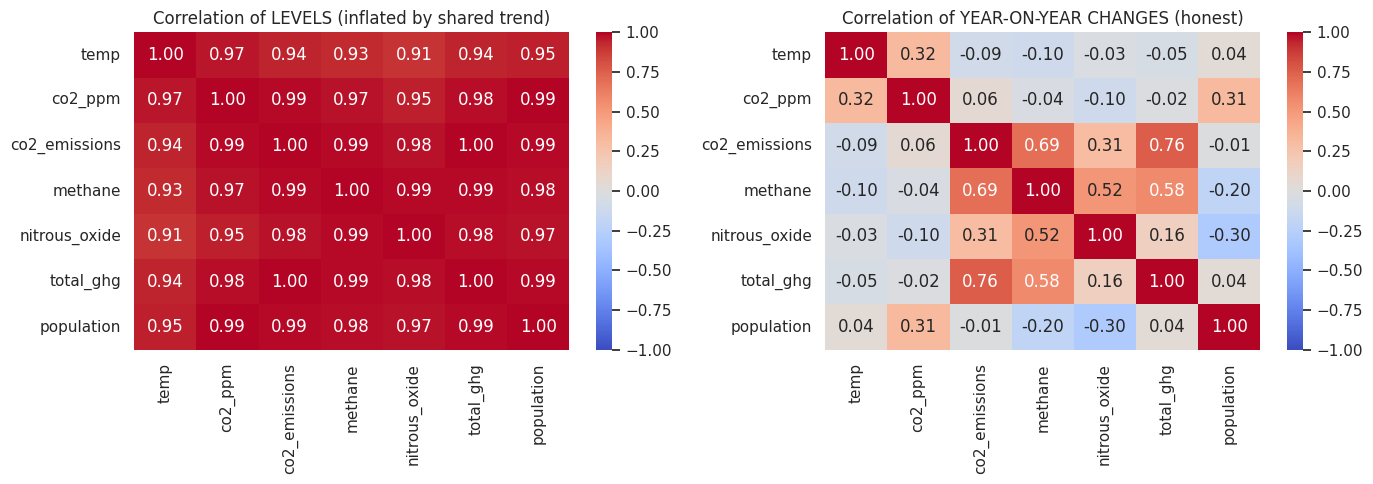

,variable,n,pearson,p_pearson,spearman,pearson_on_changes,p_changes
0,co2_ppm,67,0.9672,0.0,0.9550,0.3194,0.0089
1,co2_emissions,67,0.9442,0.0,0.9546,-0.0898,0.4733
2,methane,67,0.9293,0.0,0.9518,-0.1039,0.4065
3,nitrous_oxide,67,0.9059,0.0,0.9537,-0.0256,0.8384
4,total_ghg,67,0.9386,0.0,0.9502,-0.0520,0.6785
5,population,67,0.9530,0.0,0.9550,0.0404,0.7474


Lead-lag corr(Δtemp_t, Δco2_{t-k}): {0: np.float64(0.319), 1: np.float64(-0.237), 2: np.float64(0.03), 3: np.float64(0.21), 4: np.float64(0.078)}
Granger p-values (CO2 → temp), lag 1..3: {np.int64(1): np.float64(0.2218), np.int64(2): np.float64(0.7901), np.int64(3): np.float64(0.091)}
Note: correlation ≠ causation; year-on-year noise (El Niño, volcanoes) hides the slow CO₂ signal, which is why level-correlation is high and change-correlation is low.


In [14]:
# 6.5 Correlation analysis (annual)
from scipy import stats
ann_t = monthly.temp_anomaly.groupby(monthly.index.year).agg(['mean', 'count']); ann_t = ann_t[ann_t['count'] == 12]['mean'].rename('temp')
ann_c = monthly.co2_ppm.groupby(monthly.index.year).agg(['mean', 'count']); ann_c = ann_c[ann_c['count'] == 12]['mean'].rename('co2_ppm')
A = pd.concat([ann_t, ann_c, annual_ghg], axis=1).loc[1959:].dropna(subset=['temp', 'co2_ppm'])
print('Annual rows used:', len(A), '| columns:', list(A.columns))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(A.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax[0]); ax[0].set_title('Correlation of LEVELS (inflated by shared trend)')
sns.heatmap(A.diff().corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax[1]); ax[1].set_title('Correlation of YEAR-ON-YEAR CHANGES (honest)')
plt.tight_layout(); plt.show()

rows = []
for c in [c for c in A.columns if c != 'temp']:
    pair = A[['temp', c]].dropna()
    r, p = stats.pearsonr(pair.temp, pair[c]); rs, ps = stats.spearmanr(pair.temp, pair[c])
    dp = pair.diff().dropna(); rd, pd_ = stats.pearsonr(dp.temp, dp[c])
    rows.append(dict(variable=c, n=len(pair), pearson=r, p_pearson=p, spearman=rs, pearson_on_changes=rd, p_changes=pd_))
corr_table = pd.DataFrame(rows).round(4); display(corr_table)

# lead-lag + Granger causality (does past CO2 change help predict temperature change?)
import io, contextlib
from statsmodels.tsa.stattools import grangercausalitytests
dd = A[['temp', 'co2_ppm']].diff().dropna()
print('Lead-lag corr(Δtemp_t, Δco2_{t-k}):', {k: round(dd.temp.corr(dd.co2_ppm.shift(k)), 3) for k in range(0, 5)})
try:
    gc = grangercausalitytests(dd[['temp', 'co2_ppm']], maxlag=3, verbose=False)
except TypeError:                                   # newer statsmodels removed `verbose`
    with contextlib.redirect_stdout(io.StringIO()):
        gc = grangercausalitytests(dd[['temp', 'co2_ppm']], maxlag=3)
print('Granger p-values (CO2 → temp), lag 1..3:', {k: round(v[0]['ssr_ftest'][1], 4) for k, v in gc.items()})
print('Note: correlation ≠ causation; year-on-year noise (El Niño, volcanoes) hides the slow CO₂ signal, which is why level-correlation is high and change-correlation is low.')

## 7. Feature engineering (leakage-proof)
**Target:** the deviation of this month's anomaly from the *recent level* (`base` = mean of the previous 12 months).
Why: the raw series trends upward, and tree models cannot predict values higher than anything they saw in training. Predicting the *deviation* is stationary, so models generalise to warmer, never-seen years.
`prediction = base + predicted deviation`.

Every feature at month *t* uses only data **up to t-1**. A test below proves it.

In [15]:
FEATS = ['dev_lag1', 'dev_lag2', 'dev_lag3', 'dev_lag6', 'dev_lag12', 'dev_roll3', 'dev_roll6',
         'vol12', 'trend12', 'co2_d12', 'm_sin', 'm_cos']

def make_features(df):
    """df: monthly index with columns temp_anomaly, co2_trend. Row t uses ONLY information up to t-1."""
    y = df['temp_anomaly']
    base = y.shift(1).rolling(12).mean()
    f = pd.DataFrame(index=df.index); f['base'] = base
    for k in [1, 2, 3, 6, 12]:
        f[f'dev_lag{k}'] = y.shift(k) - base
    f['dev_roll3'] = y.shift(1).rolling(3).mean() - base
    f['dev_roll6'] = y.shift(1).rolling(6).mean() - base
    f['vol12'] = y.shift(1).rolling(12).std()
    f['trend12'] = base - base.shift(12)                         # recent warming momentum
    f['co2_d12'] = df['co2_trend'].shift(1) - df['co2_trend'].shift(13)
    mth = df.index.month
    f['m_sin'] = np.sin(2 * np.pi * mth / 12); f['m_cos'] = np.cos(2 * np.pi * mth / 12)
    return f

# ---- LEAKAGE TEST: changing today's value must NOT change today's features ----
t0 = monthly[['temp_anomaly', 'co2_trend']].copy(); t1 = t0.copy()
pos = 600; t1.iloc[pos, 0] += 5.0
F0, F1 = make_features(t0), make_features(t1)
pd.testing.assert_series_equal(F0.iloc[pos], F1.iloc[pos])                    # same features at t
assert not np.allclose(F0.iloc[pos + 1], F1.iloc[pos + 1], equal_nan=True)   # but they do affect the FUTURE
print('✅ Leakage test passed: features at month t never see month t.')

✅ Leakage test passed: features at month t never see month t.


## 8. Chronological split: Train | Validation | Test | **New (unseen)**
* **Train**: fit models and tune hyper-parameters (time-series CV inside train).
* **Validation**: choose the best model.
* **Test**: one honest final score.
* **New**: the last 12 months, never used for fitting, selection, scaling or intervals; later pushed through the production "new data" pipeline.

Train        : 1959-04-01 → 2009-10-01  (607 months)  mean=+0.24 °C
Validation   : 2009-11-01 → 2017-10-01  (96 months)  mean=+0.77 °C
Test         : 2017-11-01 → 2025-10-01  (96 months)  mean=+1.02 °C
NEW (unseen) : 2025-11-01 → 2026-10-01  (12 months)  mean=+1.25 °C


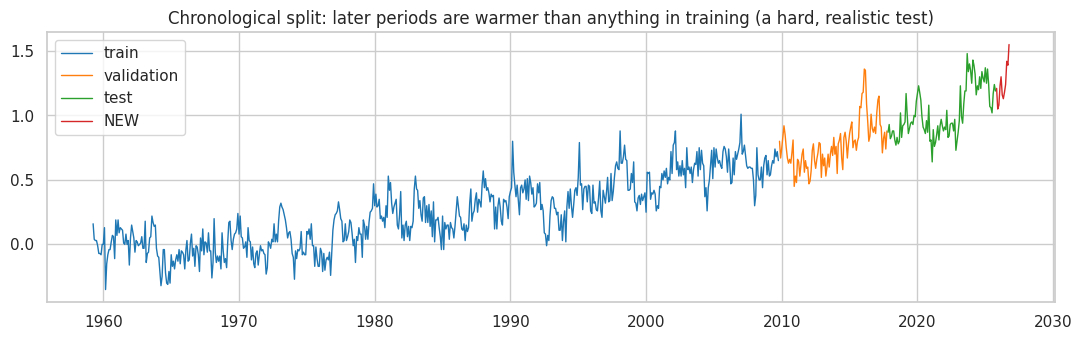

In [16]:
FX = make_features(monthly)
Y = monthly['temp_anomaly']
ok = FX[FEATS + ['base']].notna().all(axis=1) & Y.notna() & (FX.index >= pd.Timestamp(CONFIG['MODEL_START']))
dates = FX.index[ok]
n_new, n_te, n_va = CONFIG['NEW_MONTHS'], CONFIG['TEST_MONTHS'], CONFIG['VAL_MONTHS']
idx_new = dates[-n_new:]
idx_te  = dates[-(n_new + n_te):-n_new]
idx_va  = dates[-(n_new + n_te + n_va):-(n_new + n_te)]
idx_tr  = dates[:-(n_new + n_te + n_va)]
for nm, ix in [('Train', idx_tr), ('Validation', idx_va), ('Test', idx_te), ('NEW (unseen)', idx_new)]:
    print(f'{nm:13s}: {ix.min().date()} → {ix.max().date()}  ({len(ix)} months)  mean={Y.loc[ix].mean():+.2f} °C')

fig, ax = plt.subplots(figsize=(13, 3.5))
for nm, ix, c in [('train', idx_tr, 'tab:blue'), ('validation', idx_va, 'tab:orange'), ('test', idx_te, 'tab:green'), ('NEW', idx_new, 'tab:red')]:
    ax.plot(ix, Y.loc[ix], color=c, lw=1, label=nm)
ax.legend(); ax.set_title('Chronological split: later periods are warmer than anything in training (a hard, realistic test)'); plt.show()

## 9. Evaluation metrics & baselines
Metrics: **MAE, RMSE, R², Bias, MASE, Skill vs persistence, Directional accuracy**.
*MAPE is deliberately not used because anomalies cross zero (division by ~0).*
**Skill > 0 / MASE < 1** means the model beats the naive "next month = last month" forecast, the honest bar any climate model must clear.

In [17]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

def metrics(y, p, ref):
    """ref = persistence forecast (last month's value)."""
    y, p, ref = map(lambda a: np.asarray(a, float), (y, p, ref)); e = y - p
    mae = np.mean(np.abs(e)); mse = np.mean(e ** 2)
    return {'MAE': mae, 'RMSE': np.sqrt(mse),
            'R2': 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2),
            'Bias': np.mean(p - y),
            'MASE': mae / np.mean(np.abs(y - ref)),
            'Skill_vs_persistence': 1 - np.sum(e ** 2) / np.sum((y - ref) ** 2),
            'DirAcc': np.nan if np.allclose(p, ref) else np.mean(np.sign(p - ref) == np.sign(y - ref))}

def baseline_rows(idx, F=None, y=None):
    F = FX if F is None else F; y = Y if y is None else y
    ref = F.loc[idx, 'base'] + F.loc[idx, 'dev_lag1']
    return {'Baseline: persistence (y[t-1])': metrics(y.loc[idx], ref, ref),
            'Baseline: 12-month mean': metrics(y.loc[idx], F.loc[idx, 'base'], ref),
            'Baseline: same month last year': metrics(y.loc[idx], F.loc[idx, 'base'] + F.loc[idx, 'dev_lag12'], ref)}
display(pd.DataFrame(baseline_rows(idx_va)).T.round(4).style.set_caption('Baselines on VALIDATION'))

,MAE,RMSE,R2,Bias,MASE,Skill_vs_persistence,DirAcc
Baseline: persistence (y[t-1]),0.099300,0.120400,0.558700,-0.002400,1.000000,0.000000,nan
Baseline: 12-month mean,0.110400,0.139600,0.406500,-0.015100,1.112100,-0.344900,0.593800
Baseline: same month last year,0.145900,0.179900,0.013500,-0.034300,1.470100,-1.235500,0.604200


## 10. Model training
Models: **Ridge**, **Random Forest**, **Gradient Boosting** (hyper-parameters tuned with `TimeSeriesSplit` *inside the training period only*), a **Keras LSTM on GPU**, and an **Ensemble** (average).

In [18]:
MODEL_NAMES = ['Ridge', 'RandomForest', 'GradBoost', 'LSTM']
SK_SPECS = {
    'Ridge': (Pipeline([('sc', StandardScaler()), ('m', Ridge())]), {'m__alpha': [0.1, 1, 10, 100, 1000]}),
    'RandomForest': (RandomForestRegressor(random_state=SEED, n_jobs=-1),
                     {'n_estimators': [300], 'max_depth': [3, 5, 8], 'min_samples_leaf': [3, 10, 20]}),
    'GradBoost': (GradientBoostingRegressor(random_state=SEED),
                  {'n_estimators': [150, 300], 'learning_rate': [0.02, 0.05], 'max_depth': [2, 3], 'subsample': [0.8]}),
}

def xy(df, idx):
    F = make_features(df).loc[idx]
    return F[FEATS], F['base'], df['temp_anomaly'].loc[idx]

@monitored
def tune_sklearn(idx_fit):
    X, b, y = xy(monthly, idx_fit); fitted, params = {}, {}
    for name, (est, grid) in SK_SPECS.items():
        gs = GridSearchCV(est, grid, cv=TimeSeriesSplit(n_splits=5), scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X, y - b)
        fitted[name], params[name] = gs.best_estimator_, gs.best_params_
        print(f'{name:13s} best={gs.best_params_}  time-series-CV RMSE={-gs.best_score_:.4f}')
    return fitted, params

M_tr, best_params = tune_sklearn(idx_tr)          # models trained on TRAIN only

Ridge         best={'m__alpha': 10}  time-series-CV RMSE=0.1096
RandomForest  best={'max_depth': 5, 'min_samples_leaf': 3, 'n_estimators': 300}  time-series-CV RMSE=0.1149
GradBoost     best={'learning_rate': 0.02, 'max_depth': 2, 'n_estimators': 150, 'subsample': 0.8}  time-series-CV RMSE=0.1152


TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
LSTM stopped; best epoch = 11


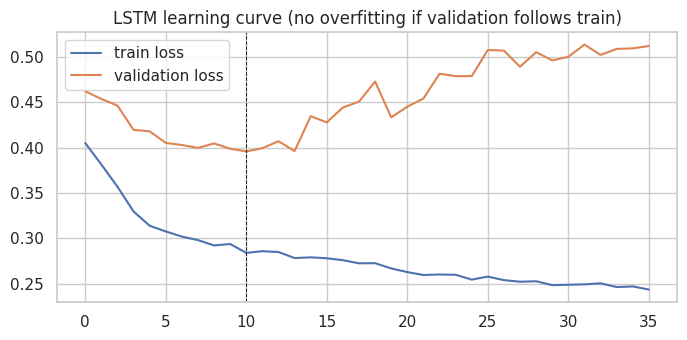

In [19]:
import tensorflow as tf
from tensorflow.keras import layers, callbacks, models
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU') or 'none (CPU is fine, data is small)')
W = CONFIG['WINDOW']

def lstm_scalers(df, idx):
    y = df.temp_anomaly; base = y.shift(1).rolling(12).mean(); c12 = df.co2_trend - df.co2_trend.shift(12)
    return dict(s_y=float((y - base).loc[idx].std()), mu_c=float(c12.loc[idx].mean()), s_c=float(c12.loc[idx].std()))

def build_windows(df, sc, dates_):
    """One sample per target month: previous W months of [deviation, sin, cos, co2 change], scaled with TRAIN statistics."""
    y = df.temp_anomaly.values.astype(float); c12 = (df.co2_trend - df.co2_trend.shift(12)).values.astype(float)
    mon = df.index.month.values; pos = df.index.get_indexer(pd.DatetimeIndex(dates_))
    X, B, T = [], [], []
    for t in pos:
        if t < max(W, 12): continue
        wy, wc = y[t - W:t], c12[t - W:t]
        if np.isnan(wy).any() or np.isnan(wc).any(): continue
        base = y[t - 12:t].mean(); ang = 2 * np.pi * mon[t - W:t] / 12
        X.append(np.stack([(wy - base) / sc['s_y'], np.sin(ang), np.cos(ang), (wc - sc['mu_c']) / sc['s_c']], 1))
        B.append(base); T.append(df.index[t])
    return np.array(X, dtype='float32'), np.array(B), pd.DatetimeIndex(T)

def build_lstm():
    m = models.Sequential([layers.Input((W, 4)), layers.LSTM(48, return_sequences=True), layers.Dropout(0.2),
                           layers.LSTM(24), layers.Dense(16, activation='relu'), layers.Dense(1)])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='huber'); return m

@monitored
def fit_lstm(df, idx_fit, idx_monitor=None, epochs=300, fixed_epochs=None):
    tf.keras.utils.set_random_seed(SEED)
    sc = lstm_scalers(df, idx_fit)
    Xf, Bf, Tf = build_windows(df, sc, idx_fit); yf = (df.temp_anomaly.loc[Tf].values - Bf) / sc['s_y']
    m = build_lstm()
    if idx_monitor is not None:
        Xm, Bm, Tm = build_windows(df, sc, idx_monitor); ym = (df.temp_anomaly.loc[Tm].values - Bm) / sc['s_y']
        cb = [callbacks.EarlyStopping(patience=25, restore_best_weights=True, monitor='val_loss'),
              callbacks.ReduceLROnPlateau(factor=.5, patience=8, min_lr=1e-5)]
        h = m.fit(Xf, yf, validation_data=(Xm, ym), epochs=epochs, batch_size=32, callbacks=cb, verbose=0)
    else:
        h = m.fit(Xf, yf, epochs=fixed_epochs, batch_size=32, verbose=0)
    return dict(model=m, sc=sc, history=h.history)

lstm_tr = fit_lstm(monthly, idx_tr, idx_monitor=idx_va)       # early stopping watches VALIDATION loss
M_tr['LSTM'] = lstm_tr
best_epoch = int(np.argmin(lstm_tr['history']['val_loss']) + 1)
print('LSTM stopped; best epoch =', best_epoch)
hh = lstm_tr['history']
plt.figure(figsize=(8, 3.5)); plt.plot(hh['loss'], label='train loss'); plt.plot(hh['val_loss'], label='validation loss')
plt.axvline(best_epoch - 1, color='k', ls='--', lw=.7); plt.legend(); plt.title('LSTM learning curve (no overfitting if validation follows train)'); plt.show()

In [20]:
def predict(name, M, hist, dates_):
    """Unified predictor. Returns a Series of predicted temp_anomaly for `dates_`, using only data before each date."""
    dates_ = pd.DatetimeIndex(dates_)
    if name == 'LSTM':
        X, B, T = build_windows(hist, M['LSTM']['sc'], dates_)
        return pd.Series(M['LSTM']['model'](X, training=False).numpy()[:, 0] * M['LSTM']['sc']['s_y'] + B, index=T)
    if name == 'Ensemble':
        return pd.concat([predict(n, M, hist, dates_) for n in MODEL_NAMES], axis=1).mean(axis=1)
    F = make_features(hist).loc[dates_]
    return pd.Series(F['base'].values + M[name].predict(F[FEATS]), index=F.index)

def score_table(M, idx, title):
    rows = baseline_rows(idx); y = Y.loc[idx]; ref = FX.loc[idx, 'base'] + FX.loc[idx, 'dev_lag1']
    for n in MODEL_NAMES + ['Ensemble']:
        p = predict(n, M, monthly, idx).reindex(idx); rows[n] = metrics(y, p, ref)
    t = pd.DataFrame(rows).T
    display(t.round(4).style.set_caption(title).background_gradient(subset=['RMSE', 'MAE'], cmap='RdYlGn_r'))
    return t

val_table = score_table(M_tr, idx_va, 'VALIDATION (models trained on TRAIN only)  → used to pick the best model')
cands = val_table.loc[MODEL_NAMES + ['Ensemble']]
BEST = cands['RMSE'].idxmin()
BEST_SK = val_table.loc[['Ridge', 'RandomForest', 'GradBoost'], 'RMSE'].idxmin()
print(f'➡ Best on validation: {BEST} | best classical model: {BEST_SK}')
print('Beats persistence baseline?' , 'YES' if val_table.loc[BEST, 'Skill_vs_persistence'] > 0 else 'NO (report this honestly)')

,MAE,RMSE,R2,Bias,MASE,Skill_vs_persistence,DirAcc
Baseline: persistence (y[t-1]),0.099300,0.120400,0.558700,-0.002400,1.000000,0.000000,nan
Baseline: 12-month mean,0.110400,0.139600,0.406500,-0.015100,1.112100,-0.344900,0.593800
Baseline: same month last year,0.145900,0.179900,0.013500,-0.034300,1.470100,-1.235500,0.604200
Ridge,0.096200,0.115600,0.592600,-0.000700,0.968700,0.076700,0.604200
RandomForest,0.092800,0.113800,0.605700,-0.000600,0.934500,0.106400,0.583300
GradBoost,0.095000,0.115700,0.592400,-0.005600,0.956800,0.076400,0.583300
LSTM,0.100400,0.125700,0.519000,-0.034500,1.011600,-0.090000,0.656200
Ensemble,0.092600,0.113700,0.606400,-0.010300,0.933200,0.108100,0.572900


➡ Best on validation: Ensemble | best classical model: RandomForest
Beats persistence baseline? YES


### 10.1 Final fit on Train+Validation → one honest score on TEST
The test period (2010s-2020s) is **warmer than anything in the training data**, a genuine stress test for "will it predict correctly on new data?".

In [21]:
@monitored
def fit_all(df, idx_fit, lstm_epochs):
    X, b, y = xy(df, idx_fit); M = {}
    for name, (est, _) in SK_SPECS.items():
        M[name] = clone(est).set_params(**best_params[name]).fit(X, y - b)
    M['LSTM'] = fit_lstm(df, idx_fit, fixed_epochs=lstm_epochs)
    return M

idx_trva = idx_tr.append(idx_va)
M_tv = fit_all(monthly, idx_trva, best_epoch)
test_table = score_table(M_tv, idx_te, 'TEST (models trained on Train+Validation)  → final honest score')

,MAE,RMSE,R2,Bias,MASE,Skill_vs_persistence,DirAcc
Baseline: persistence (y[t-1]),0.089500,0.113700,0.649600,-0.003200,1.000000,0.000000,nan
Baseline: 12-month mean,0.103800,0.138700,0.478900,-0.020500,1.159900,-0.487000,0.635400
Baseline: same month last year,0.154600,0.206000,-0.149900,-0.037500,1.727600,-2.281600,0.531200
Ridge,0.082400,0.105400,0.699000,-0.002500,0.921000,0.141100,0.625000
RandomForest,0.080900,0.104800,0.702400,-0.008900,0.904200,0.150600,0.666700
GradBoost,0.083100,0.107400,0.687700,-0.010200,0.928700,0.108900,0.677100
LSTM,0.085100,0.112700,0.656000,-0.019600,0.950800,0.018300,0.656200
Ensemble,0.080900,0.105000,0.701200,-0.010300,0.904200,0.147400,0.677100


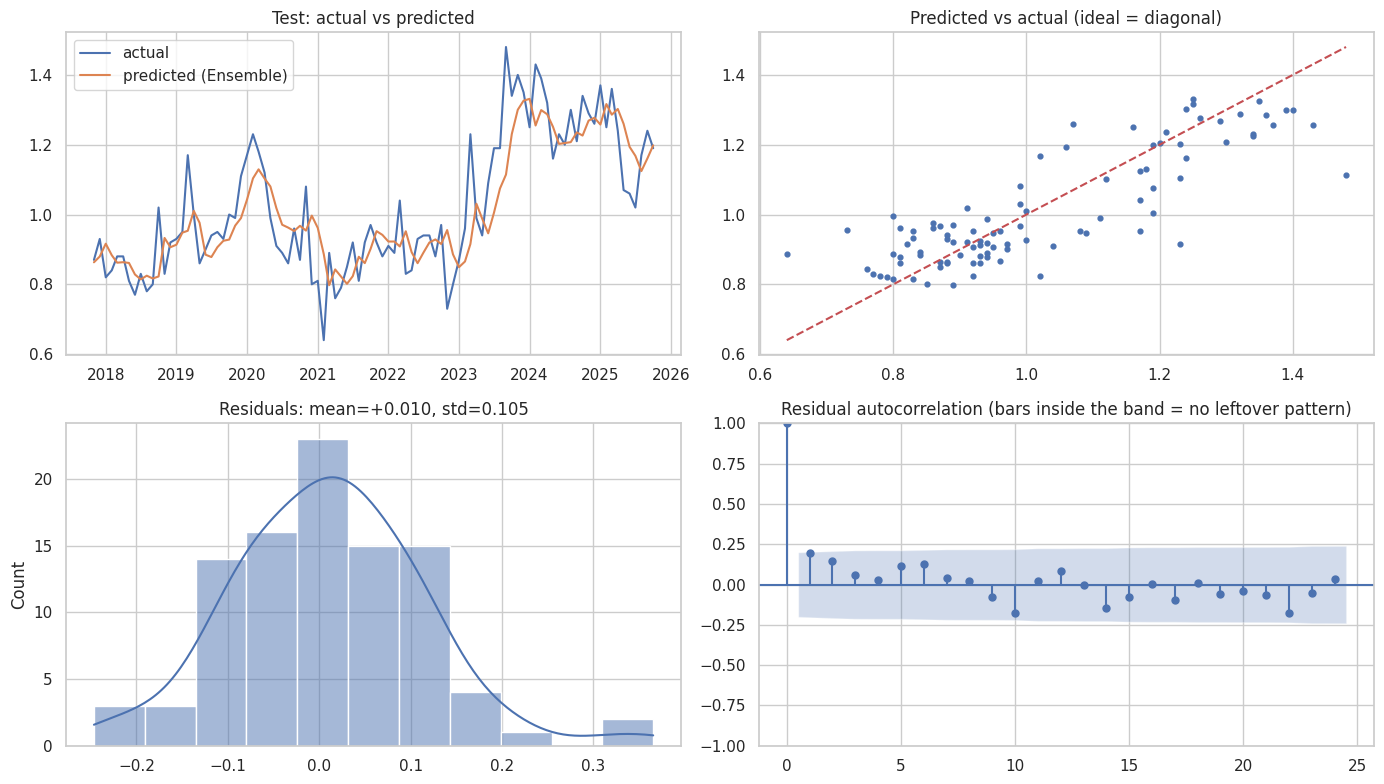

Error by calendar month (RMSE):
{1: 0.093, 2: 0.124, 3: 0.153, 4: 0.06, 5: 0.097, 6: 0.088, 7: 0.099, 8: 0.074, 9: 0.135, 10: 0.104, 11: 0.106, 12: 0.092}


In [22]:
# Actual vs predicted + residual diagnostics for the chosen model
from statsmodels.graphics.tsaplots import plot_acf
p_te = predict(BEST, M_tv, monthly, idx_te).reindex(idx_te); y_te = Y.loc[idx_te]; res_te = y_te - p_te
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax[0, 0].plot(idx_te, y_te, label='actual'); ax[0, 0].plot(idx_te, p_te, label=f'predicted ({BEST})'); ax[0, 0].legend(); ax[0, 0].set_title('Test: actual vs predicted')
ax[0, 1].scatter(y_te, p_te, s=12); lim = [min(y_te.min(), p_te.min()), max(y_te.max(), p_te.max())]; ax[0, 1].plot(lim, lim, 'r--'); ax[0, 1].set_title('Predicted vs actual (ideal = diagonal)')
sns.histplot(res_te, kde=True, ax=ax[1, 0]); ax[1, 0].set_title(f'Residuals: mean={res_te.mean():+.3f}, std={res_te.std():.3f}')
plot_acf(res_te, lags=24, ax=ax[1, 1]); ax[1, 1].set_title('Residual autocorrelation (bars inside the band = no leftover pattern)')
plt.tight_layout(); plt.show()
print('Error by calendar month (RMSE):'); print(res_te.groupby(res_te.index.month).apply(lambda r: np.sqrt((r ** 2).mean())).round(3).to_dict())

### 10.2 Prediction intervals (an honest uncertainty range)
Interval half-width = the 90th percentile of absolute errors on **validation** (out-of-sample). We then verify the **coverage on test** (should be ≈ 90%).

In [23]:
p_va = predict(BEST, M_tr, monthly, idx_va).reindex(idx_va); res_va = Y.loc[idx_va] - p_va
HALF = float(np.quantile(np.abs(res_va), CONFIG['INTERVAL']))
SIGMA = float(1.4826 * np.median(np.abs(res_va - np.median(res_va))))       # robust std of one-step error
inside = (np.abs(Y.loc[idx_te] - p_te) <= HALF).mean()
print(f'Interval half-width = ±{HALF:.3f} °C | robust σ = {SIGMA:.3f} °C')
print(f'Empirical coverage on TEST = {inside:.1%} (target {CONFIG["INTERVAL"]:.0%})')

Interval half-width = ±0.180 °C | robust σ = 0.124 °C
Empirical coverage on TEST = 90.6% (target 90%)


### 10.3 Walk-forward re-training (requirement: *models are regularly updated with the latest data*)
Instead of fitting once, the model is **re-fitted every 12 months** using all data available at that time, exactly what happens in production.

In [24]:
def walk_forward(name, step=12):
    out = []
    for i in range(0, len(idx_te), step):
        blk = idx_te[i:i + step]; fit_idx = dates[dates < blk[0]]
        X, b, y = xy(monthly, fit_idx); est = clone(SK_SPECS[name][0]).set_params(**best_params[name]).fit(X, y - b)
        F = FX.loc[blk]; out.append(pd.Series(F['base'].values + est.predict(F[FEATS]), index=blk))
    return pd.concat(out)

ref_te = FX.loc[idx_te, 'base'] + FX.loc[idx_te, 'dev_lag1']
wf = walk_forward(BEST_SK)
cmp_ = pd.DataFrame({'Fixed model (fit once)': metrics(Y.loc[idx_te], predict(BEST_SK, M_tv, monthly, idx_te).reindex(idx_te), ref_te),
                     'Walk-forward (re-fit yearly)': metrics(Y.loc[idx_te], wf.reindex(idx_te), ref_te)}).T
display(cmp_.round(4).style.set_caption(f'{BEST_SK}: effect of regular re-training on TEST'))

,MAE,RMSE,R2,Bias,MASE,Skill_vs_persistence,DirAcc
Fixed model (fit once),0.080900,0.104800,0.702400,-0.008900,0.904200,0.150600,0.666700
Walk-forward (re-fit yearly),0.081300,0.104600,0.703600,-0.006600,0.908400,0.154200,0.635400


### 10.4 Multi-step (12-month) forecast accuracy: how fast does skill decay?
Recursive forecasting: predict month 1, feed it back, predict month 2, … Origins are every 3 months across the test period; the actual future is known so we can measure error **per horizon**.

h,1,2,3,4,5,6,7,8,9,10,11,12
RMSE_model,0.100,0.138,0.119,0.131,0.161,0.150,0.173,0.199,0.176,0.190,0.212,0.186
RMSE_persistence,0.105,0.132,0.109,0.126,0.151,0.147,0.166,0.201,0.178,0.187,0.217,0.185
RMSE_mean12,0.133,0.170,0.142,0.163,0.194,0.165,0.191,0.216,0.187,0.208,0.226,0.203
n,29.000,29.000,29.000,29.000,29.000,29.000,29.000,29.000,29.000,29.000,29.000,29.000


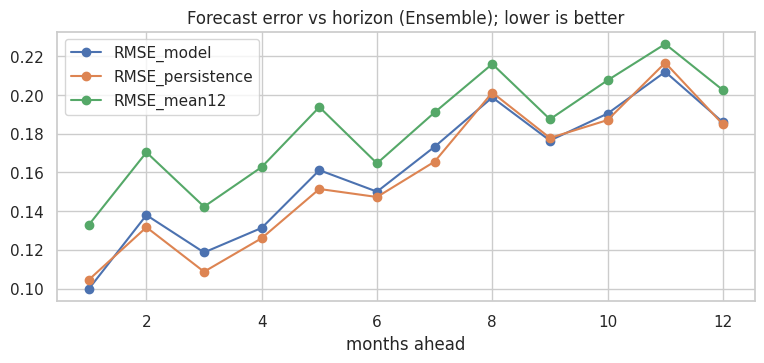

In [25]:
def extend_co2(c, n, k=60):
    c = np.asarray(c, float)[-k:]; sl, ic = np.polyfit(np.arange(len(c)), c, 1)
    return ic + sl * np.arange(len(c), len(c) + n)

def recursive_forecast(name, M, hist, horizon):
    h = hist[['temp_anomaly', 'co2_trend']].iloc[-96:].copy()
    h['co2_trend'] = h['co2_trend'].interpolate().ffill()
    fut = extend_co2(h['co2_trend'].values, horizon); out = {}
    for i in range(horizon):
        nd = h.index[-1] + pd.offsets.MonthBegin(1)
        h.loc[nd] = [np.nan, fut[i]]
        yhat = float(predict(name, M, h, [nd]).iloc[0])
        h.loc[nd, 'temp_anomaly'] = yhat; out[nd] = yhat
    return pd.Series(out)

@monitored
def horizon_backtest(name, M, step=3):
    H = CONFIG['HORIZON']; recs = []
    origins = [d for d in dates[(dates >= idx_te[0] - pd.offsets.MonthBegin(1)) & (dates <= idx_te[-1])]][::step]
    for o in origins:
        if o + pd.DateOffset(months=H) > idx_te[-1]: break
        f = recursive_forecast(name, M, monthly.loc[:o], H); actual = Y.reindex(f.index)
        last, mean12 = monthly.temp_anomaly.loc[:o].iloc[-1], monthly.temp_anomaly.loc[:o].iloc[-12:].mean()
        for h_, (dt, yh) in enumerate(f.items(), 1):
            recs.append(dict(origin=o, h=h_, err=actual[dt] - yh, err_persist=actual[dt] - last, err_mean12=actual[dt] - mean12))
    return pd.DataFrame(recs)

hb = horizon_backtest(BEST, M_tv)
hz = hb.groupby('h').agg(RMSE_model=('err', lambda e: np.sqrt((e ** 2).mean())),
                         RMSE_persistence=('err_persist', lambda e: np.sqrt((e ** 2).mean())),
                         RMSE_mean12=('err_mean12', lambda e: np.sqrt((e ** 2).mean())),
                         n=('err', 'size'))
HZ_HALF = hb.groupby('h')['err'].apply(lambda e: np.quantile(np.abs(e), CONFIG['INTERVAL'])).cummax()   # widening intervals
display(hz.round(3).T)
ax = hz[['RMSE_model', 'RMSE_persistence', 'RMSE_mean12']].plot(marker='o', figsize=(9, 3.5)); ax.set_title(f'Forecast error vs horizon ({BEST}); lower is better'); ax.set_xlabel('months ahead'); plt.show()

## 11. Anomaly detection (with a real accuracy score)
There are no ground-truth labels for climate anomalies, so accuracy is measured honestly with **synthetic injected anomalies** (sensor glitches / extreme events of random size and sign) on the test period. 20 random trials, averaged.
Three detectors: **(a)** prediction-residual z-score (model says "this was unexpected"), **(b)** robust rolling z-score (median/MAD), **(c)** Isolation Forest. Plus a **vote** (≥2 agree).

In [26]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_fscore_support

def robust_z(y, win=24):
    prev = y.shift(1); med = prev.rolling(win).median()
    mad = prev.rolling(win).apply(lambda a: np.median(np.abs(a - np.median(a))), raw=True) * 1.4826
    return (y - med) / mad

def iso_frame(df):
    F = make_features(df)
    X = F[['dev_lag1', 'dev_lag2', 'vol12']].copy()          # stationary features only (trend12 drifts upward)
    X['cur_dev'] = df.temp_anomaly - F['base']
    return X
iso = IsolationForest(n_estimators=300, contamination=0.02, random_state=SEED).fit(iso_frame(monthly).loc[idx_tr])

def detect(df, idx, M=None, best=None, sigma=None):
    M = M or M_tv; best = best or BEST; sigma = sigma or SIGMA; Z = CONFIG['ANOMALY_Z']
    o = pd.DataFrame(index=idx); p = predict(best, M, df, idx).reindex(idx)
    o['resid_z'] = (df.temp_anomaly.loc[idx] - p) / sigma
    o['robust_z'] = robust_z(df.temp_anomaly).loc[idx]
    o['flag_residual'] = o.resid_z.abs() > Z
    o['flag_robust'] = o.robust_z.abs() > Z
    o['flag_iso'] = iso.predict(iso_frame(df).loc[idx]) == -1
    o['flag_vote'] = o[['flag_residual', 'flag_robust', 'flag_iso']].sum(axis=1) >= 2
    return o

def inject(df, idx, rng, frac=0.06, mag=(2.5, 6.0)):
    d = df.copy(); lab = pd.Series(False, index=idx)
    for dt in rng.choice(idx, int(len(idx) * frac), replace=False):
        d.loc[dt, 'temp_anomaly'] += rng.choice([-1, 1]) * rng.uniform(*mag) * SIGMA; lab[dt] = True
    return d, lab

@monitored
def anomaly_benchmark(trials=20):
    rows = []
    for s in range(trials):
        rng = np.random.default_rng(SEED + s); d, lab = inject(monthly, idx_te, rng); det = detect(d, idx_te)
        for m in ['flag_residual', 'flag_robust', 'flag_iso', 'flag_vote']:
            pr, rc, f1, _ = precision_recall_fscore_support(lab, det[m], average='binary', zero_division=0)
            rows.append(dict(method=m.replace('flag_', ''), precision=pr, recall=rc, F1=f1))
    return pd.DataFrame(rows).groupby('method').mean().round(3)

anom_scores = anomaly_benchmark()
display(anom_scores.style.set_caption('Anomaly detection on injected anomalies (mean of 20 trials)'))
real = detect(monthly, idx_te.append(idx_new))
anomalies_real = real[real[['flag_residual', 'flag_robust']].any(axis=1)][['resid_z', 'robust_z']].round(2)
print('Months flagged on REAL data (test + new):'); display(anomalies_real)

,precision,recall,F1
method,,,
iso,0.152000,0.480000,0.228000
residual,0.890000,0.820000,0.844000
robust,0.381000,0.800000,0.514000
vote,0.499000,0.800000,0.611000


Months flagged on REAL data (test + new):


,resid_z,robust_z
date,,
2019-03-01,1.75,3.68
2023-03-01,2.54,4.59
2023-07-01,1.49,4.05
2023-08-01,0.93,3.97
2023-09-01,2.95,6.68
2023-10-01,0.88,4.50
2023-11-01,0.81,4.77
2023-12-01,0.19,3.25
2026-10-01,1.53,3.04


## 12. Platform services: database, authentication, roles, alerts, feedback, encryption
SQLite stands in for MongoDB (same idea: users, alerts, feedback, settings, audit log). Passwords are **salted PBKDF2-SHA256** hashes (never stored in plain text). Access is **role-based**.

In [27]:
import io, smtplib
from email.message import EmailMessage
DB = f'{BASE}/db/earthscape.db'
def db(): return sqlite3.connect(DB)

with db() as c:
    c.executescript("""
    CREATE TABLE IF NOT EXISTS users(username TEXT PRIMARY KEY, salt TEXT, pw_hash TEXT, role TEXT);
    CREATE TABLE IF NOT EXISTS alerts(id INTEGER PRIMARY KEY AUTOINCREMENT, ts TEXT, month TEXT, value REAL, level TEXT, message TEXT);
    CREATE TABLE IF NOT EXISTS feedback(id INTEGER PRIMARY KEY AUTOINCREMENT, ts TEXT, username TEXT, category TEXT, message TEXT, status TEXT);
    CREATE TABLE IF NOT EXISTS settings(key TEXT PRIMARY KEY, value TEXT);
    CREATE TABLE IF NOT EXISTS audit(id INTEGER PRIMARY KEY AUTOINCREMENT, ts TEXT, username TEXT, action TEXT, allowed INTEGER);
    """)
    c.execute('INSERT OR IGNORE INTO settings VALUES(?,?)', ('alert_threshold', str(CONFIG['ALERT_THRESHOLD'])))

def hash_pw(pw, salt=None):
    salt = salt or secrets.token_hex(16)
    return salt, hashlib.pbkdf2_hmac('sha256', pw.encode(), bytes.fromhex(salt), 200_000).hex()

def create_user(username, pw, role):
    s, h = hash_pw(pw)
    with db() as c: c.execute('INSERT OR REPLACE INTO users VALUES(?,?,?,?)', (username, s, h, role))

PERMS = {'admin':   {'view', 'predict', 'set_threshold', 'manage_users', 'read_feedback', 'retrain'},
         'analyst': {'view', 'predict', 'submit_feedback'}}

def audit(user, action, allowed):
    with db() as c: c.execute('INSERT INTO audit(ts,username,action,allowed) VALUES(?,?,?,?)', (datetime.now().isoformat(timespec='seconds'), user, action, int(allowed)))

def login(username, pw):
    with db() as c: row = c.execute('SELECT salt,pw_hash,role FROM users WHERE username=?', (username,)).fetchone()
    ok = bool(row) and hmac.compare_digest(hash_pw(pw, row[0])[1], row[1])
    audit(username, 'login', ok)
    return {'user': username, 'role': row[2]} if ok else None

def require(session, perm):
    allowed = bool(session) and perm in PERMS.get(session['role'], set())
    audit(session['user'] if session else 'anonymous', perm, allowed)
    if not allowed: raise PermissionError(f"Role '{session['role'] if session else None}' may not '{perm}'")

# ---- demo accounts (CHANGE these passwords in real use) ----
create_user('admin', 'Admin@12345', 'admin'); create_user('analyst', 'Analyst@12345', 'analyst')

# ---- role-protected actions ----
def get_threshold():
    with db() as c: return float(c.execute("SELECT value FROM settings WHERE key='alert_threshold'").fetchone()[0])
def set_threshold(session, value):
    require(session, 'set_threshold')
    with db() as c: c.execute("UPDATE settings SET value=? WHERE key='alert_threshold'", (str(float(value)),))
def submit_feedback(session, category, message):
    require(session, 'submit_feedback')
    with db() as c: c.execute('INSERT INTO feedback(ts,username,category,message,status) VALUES(?,?,?,?,?)', (datetime.now().isoformat(timespec='seconds'), session['user'], category, message, 'open'))
def read_feedback(session):
    require(session, 'read_feedback')
    with db() as c: return pd.read_sql('SELECT * FROM feedback', c)

# ---- alerts (configurable thresholds + optional e-mail) ----
def send_email_alert(subject, body):
    u, p, to = os.getenv('ALERT_EMAIL_USER'), os.getenv('ALERT_EMAIL_PASS'), os.getenv('ALERT_EMAIL_TO')
    if not (u and p and to): return False                   # not configured → alert is still stored in the DB
    try:
        msg = EmailMessage(); msg['Subject'], msg['From'], msg['To'] = subject, u, to; msg.set_content(body)
        with smtplib.SMTP_SSL('smtp.gmail.com', 465) as s: s.login(u, p); s.send_message(msg)
        return True
    except Exception as e:
        print('e-mail failed:', e); return False

def alert_level(value, z):
    thr = get_threshold()
    if value >= thr: return 'CRITICAL'
    if value >= 0.9 * thr: return 'WARNING'
    if pd.notna(z) and abs(z) > CONFIG['ANOMALY_Z']: return 'ANOMALY'
    return 'OK'

def log_alert(month, value, level, message):
    with db() as c: c.execute('INSERT INTO alerts(ts,month,value,level,message) VALUES(?,?,?,?,?)', (datetime.now().isoformat(timespec='seconds'), str(month)[:7], float(value), level, message))
    send_email_alert(f'[EarthScape {level}] {str(month)[:7]}', message)

# ---- demo: RBAC in action ----
adm, ana = login('admin', 'Admin@12345'), login('analyst', 'Analyst@12345')
print('Wrong password →', login('analyst', 'wrong'))
try: set_threshold(ana, 1.5)
except PermissionError as e: print('Analyst blocked:', e)
set_threshold(adm, CONFIG['ALERT_THRESHOLD']); print('Admin set threshold →', get_threshold())
submit_feedback(ana, 'bug', 'Dashboard legend overlaps on mobile.'); display(read_feedback(adm))

Wrong password → None
Analyst blocked: Role 'analyst' may not 'set_threshold'
Admin set threshold → 1.5


,id,ts,username,category,message,status
0,1,2026-11-18T07:28:27,analyst,bug,Dashboard legend overlaps on mobile.,open
1,2,2026-11-18T12:14:39,analyst,bug,Dashboard legend overlaps on mobile.,open
2,3,2026-11-18T13:31:04,analyst,bug,Dashboard legend overlaps on mobile.,open


In [28]:
# ---- encryption at rest (requirement: Data Security) ----
from cryptography.fernet import Fernet
KEY_PATH = f'{BASE}/db/secret.key'          # ⚠ keep this file PRIVATE; do not include it in your submission zip
if not os.path.exists(KEY_PATH): open(KEY_PATH, 'wb').write(Fernet.generate_key())
fernet = Fernet(open(KEY_PATH, 'rb').read())
def encrypt_file(path):
    open(path + '.enc', 'wb').write(fernet.encrypt(open(path, 'rb').read())); return path + '.enc'
src = f'{BASE}/data/clean/monthly_clean.csv'; enc = encrypt_file(src)
print('Encrypted bytes (unreadable):', open(enc, 'rb').read()[:50])
back = pd.read_csv(io.BytesIO(fernet.decrypt(open(enc, 'rb').read())), index_col=0)
print('Decrypts back to identical data:', back.shape == monthly.shape)
print('(Data in transit: Colab/Drive/NOAA/NASA downloads all use HTTPS/TLS.)')

Encrypted bytes (unreadable): b'gAAAAABq_aiYQ7AgoDsQiipT_uXOZbKD3N2d6mBgIxiuUmsFSU'
Decrypts back to identical data: True
(Data in transit: Colab/Drive/NOAA/NASA downloads all use HTTPS/TLS.)


## 13. Production model (fitted on everything *before* the unseen new months) + versioned save
Models are saved with **Keras (`.keras`) for the LSTM** and **Pickle (`.pkl`) for the scikit-learn models**, plus a `metadata.json` (features, split dates, metrics, interval width).

In [29]:
idx_prod = idx_tr.append(idx_va).append(idx_te)
M_prod = fit_all(monthly, idx_prod, best_epoch)
res_oos = pd.concat([res_va, res_te])                               # all residuals here were genuinely out-of-sample
HALF_PROD = float(np.quantile(np.abs(res_oos), CONFIG['INTERVAL']))
SIGMA_PROD = float(1.4826 * np.median(np.abs(res_oos - np.median(res_oos))))
hist_prod = monthly[['temp_anomaly', 'co2_trend']].loc[:idx_te[-1]].copy()     # data known BEFORE the new months
STATE = dict(M=M_prod, best=BEST, hist=hist_prod, half=HALF_PROD, sigma=SIGMA_PROD, hz_half=HZ_HALF.to_dict())
print(f'Production model = {BEST} | interval ±{HALF_PROD:.3f} °C | knows data up to {hist_prod.index[-1].date()}')

def save_models(M, tag, extra):
    d = f'{BASE}/models/{tag}'; os.makedirs(d, exist_ok=True)
    for n in ['Ridge', 'RandomForest', 'GradBoost']: pickle.dump(M[n], open(f'{d}/{n}.pkl', 'wb'))
    M['LSTM']['model'].save(f'{d}/lstm.keras'); json.dump(M['LSTM']['sc'], open(f'{d}/lstm_scaler.json', 'w'))
    json.dump(extra, open(f'{d}/metadata.json', 'w'), indent=2, default=str); return d

def load_models(d):
    M = {n: pickle.load(open(f'{d}/{n}.pkl', 'rb')) for n in ['Ridge', 'RandomForest', 'GradBoost']}
    M['LSTM'] = dict(model=tf.keras.models.load_model(f'{d}/lstm.keras'), sc=json.load(open(f'{d}/lstm_scaler.json')), history={})
    return M

meta = dict(created=datetime.now().isoformat(timespec='seconds'), best_model=BEST, features=FEATS, window=W, best_params=best_params,
            splits={k: [str(v.min().date()), str(v.max().date())] for k, v in [('train', idx_tr), ('val', idx_va), ('test', idx_te), ('new', idx_new)]},
            half_width=HALF_PROD, sigma=SIGMA_PROD, horizon_half_width={int(k): float(v) for k, v in HZ_HALF.items()},
            validation_metrics=val_table.round(5).to_dict('index'), test_metrics=test_table.round(5).to_dict('index'))
MODEL_DIR = save_models(M_prod, 'v1_' + datetime.now().strftime('%Y%m%d_%H%M'), meta)
print('Saved →', MODEL_DIR, os.listdir(MODEL_DIR))

# prove the saved files reproduce the same predictions
M_loaded = load_models(MODEL_DIR)
a = predict(BEST, M_prod, monthly, idx_new); b = predict(BEST, M_loaded, monthly, idx_new)
print('Reloaded models give identical predictions:', bool(np.allclose(a.values, b.values, atol=1e-5)))

Production model = Ensemble | interval ±0.175 °C | knows data up to 2025-10-01
Saved → /content/drive/MyDrive/EarthScape/models/v1_20261118_1331 ['Ridge.pkl', 'RandomForest.pkl', 'GradBoost.pkl', 'lstm.keras', 'lstm_scaler.json', 'metadata.json']
Reloaded models give identical predictions: True


## 14. 🔮 Predicting on **new, unseen data**
`predict_new()` is the production entry point. For every incoming month it: **validates** the record → predicts that month using **only earlier data** → compares with the actual value → computes interval, anomaly score and alert level → appends the actual to the history.
The 12 hold-out months have never been touched by training, tuning, scaling or interval estimation, so this is the real "new data" test.

In [30]:
def validate_new(new_df):
    need = {'temp_anomaly', 'co2_trend'}
    if not need <= set(new_df.columns): raise ValueError(f'Missing columns: {need - set(new_df.columns)}')
    d = new_df[['temp_anomaly', 'co2_trend']].copy()
    d.index = pd.DatetimeIndex(pd.to_datetime(d.index)).to_period('M').to_timestamp()
    d = d[~d.index.duplicated(keep='last')].sort_index()
    for c in d: d[c] = pd.to_numeric(d[c], errors='coerce')
    d.loc[d.temp_anomaly.abs() > 6, 'temp_anomaly'] = np.nan          # physically implausible → treated as missing
    return d

@monitored
def predict_new(new_df, state=None, log=False):
    S = state or STATE; d = validate_new(new_df); hist = S['hist'].copy(); rows = []
    expected = hist.index[-1] + pd.offsets.MonthBegin(1)
    if d.index[0] != expected: raise ValueError(f'New data must start at {expected.date()} (got {d.index[0].date()}); no gaps allowed.')
    for dt, r in d.iterrows():
        co2 = r.co2_trend if pd.notna(r.co2_trend) else float(extend_co2(hist.co2_trend.interpolate().ffill().values, 1)[0])
        hist.loc[dt] = [np.nan, co2]
        yhat = float(predict(S['best'], S['M'], hist, [dt]).iloc[0])            # uses ONLY data before dt
        imputed = pd.isna(r.temp_anomaly); actual = yhat if imputed else float(r.temp_anomaly)
        z = np.nan if imputed else (actual - yhat) / S['sigma']
        level = alert_level(actual, z); hist.loc[dt, 'temp_anomaly'] = actual
        rows.append(dict(month=dt, actual=actual, predicted=yhat, lower=yhat - S['half'], upper=yhat + S['half'],
                         error=np.nan if imputed else actual - yhat, in_interval=np.nan if imputed else abs(actual - yhat) <= S['half'],
                         z=z, level=level, imputed=imputed))
        if log and level != 'OK':
            log_alert(dt, actual, level, f'{level}: {dt:%Y-%m} anomaly {actual:+.2f}°C (model expected {yhat:+.2f}, z={z:+.1f})')
    return pd.DataFrame(rows).set_index('month'), hist

new_in = monthly.loc[idx_new, ['temp_anomaly', 'co2_trend']]
res_new, _ = predict_new(new_in)
display(res_new.round(3))

,actual,predicted,lower,upper,error,in_interval,z,level,imputed
month,,,,,,,,,
2025-11-01,1.21,1.204,1.029,1.379,0.006,True,0.051,OK,False
2025-12-01,1.05,1.212,1.037,1.386,-0.162,True,-1.407,OK,False
2026-01-01,1.08,1.158,0.983,1.333,-0.078,True,-0.679,OK,False
2026-02-01,1.23,1.122,0.947,1.296,0.108,True,0.944,OK,False
2026-03-01,1.30,1.175,1.000,1.350,0.125,True,1.088,OK,False
2026-04-01,1.16,1.212,1.037,1.387,-0.052,True,-0.452,OK,False
2026-05-01,1.13,1.163,0.988,1.337,-0.033,True,-0.284,OK,False
2026-06-01,1.18,1.136,0.961,1.310,0.044,True,0.386,OK,False
2026-07-01,1.24,1.168,0.993,1.342,0.072,True,0.629,OK,False


,MAE,RMSE,R2,Bias,MASE,Skill_vs_persistence,DirAcc
Ensemble (production),0.094400,0.111800,0.372500,-0.040400,1.048800,-0.073200,0.500000
Baseline: persistence,0.090000,0.107900,0.415300,-0.030000,1.000000,0.000000,nan
Baseline: 12-month mean,0.112900,0.150000,-0.129700,-0.066700,1.254600,-0.932200,0.666700


Interval coverage on new data: 83% (target 90%)
ℹ️ On these few unseen months the model is NOT better than "same as last month". With n=12 this is noisy, and the drift test below shows why (recent warming is faster than in the training years). Report it honestly and rely on re-training (Section 16).


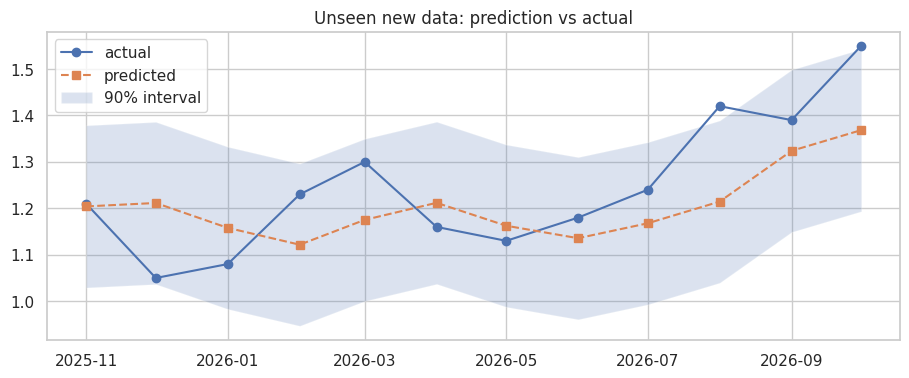

,feature,KS_stat,p_value,drift
0,dev_lag1,0.235,0.4625,False
1,trend12,0.560,0.0005,True
2,co2_d12,0.502,0.0029,True
3,vol12,0.320,0.1437,False


If drift=True for several features → retrain (Section 16).


In [31]:
# Score on the unseen new months vs naive baselines
last_known = hist_prod.temp_anomaly.iloc[-1]
ref_new = np.r_[last_known, res_new.actual.values[:-1]]                      # persistence forecast
mean12_new = np.array([pd.concat([hist_prod.temp_anomaly, res_new.actual]).iloc[:len(hist_prod) + i].iloc[-12:].mean() for i in range(len(res_new))])
new_scores = pd.DataFrame({f'{BEST} (production)': metrics(res_new.actual, res_new.predicted, ref_new),
                           'Baseline: persistence': metrics(res_new.actual, ref_new, ref_new),
                           'Baseline: 12-month mean': metrics(res_new.actual, mean12_new, ref_new)}).T
display(new_scores.round(4).style.set_caption(f'UNSEEN NEW DATA ({len(res_new)} months). Small n, so read with care'))
print(f'Interval coverage on new data: {res_new.in_interval.mean():.0%} (target {CONFIG["INTERVAL"]:.0%})')
if new_scores.iloc[0]['Skill_vs_persistence'] <= 0:
    print('ℹ️ On these few unseen months the model is NOT better than "same as last month". With n=12 this is noisy, and the drift test below shows why (recent warming is faster than in the training years). Report it honestly and rely on re-training (Section 16).')

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(res_new.index, res_new.actual, 'o-', label='actual'); ax.plot(res_new.index, res_new.predicted, 's--', label='predicted')
ax.fill_between(res_new.index, res_new.lower, res_new.upper, alpha=.2, label=f'{CONFIG["INTERVAL"]:.0%} interval'); ax.legend(); ax.set_title('Unseen new data: prediction vs actual'); plt.show()

# ---- data-drift check: does the new data look like the training data? ----
from scipy.stats import ks_2samp
drift = []
for f in ['dev_lag1', 'trend12', 'co2_d12', 'vol12']:
    ks = ks_2samp(FX.loc[idx_tr, f], FX.loc[idx_new, f]); drift.append(dict(feature=f, KS_stat=round(ks.statistic, 3), p_value=round(ks.pvalue, 4), drift=ks.pvalue < 0.01))
display(pd.DataFrame(drift)); print('If drift=True for several features → retrain (Section 16).')

## 15. Real-time streaming (replay) integrated with batch history (Lambda architecture)
The 12 new months arrive **one by one**. Each reading is validated, predicted from the batch history, compared, alerted on, then **appended to the history** (batch + speed layers share one history). A sensor spike is injected at reading 6 to prove the alerting works.

In [32]:
@monitored
def stream_replay(new_df, delay=0.2, spike_at=None, spike=0.9):
    S = dict(STATE); S['hist'] = STATE['hist'].copy(); out = []
    for i, (dt, r) in enumerate(new_df.iterrows()):
        row = r.copy()
        if spike_at == i: row['temp_anomaly'] += spike; print('   💥 simulated sensor spike injected')
        res, S['hist'] = predict_new(pd.DataFrame([row.values], index=[dt], columns=new_df.columns), state=S, log=True)
        x = res.iloc[0]; out.append(res)
        print(f'{dt:%Y-%m}  actual={x.actual:+.2f}  pred={x.predicted:+.2f}  [{x.lower:+.2f},{x.upper:+.2f}]  z={x.z:+.1f}  → {x.level}')
        time.sleep(delay)
    return pd.concat(out), S['hist']

stream_df, hist_after_stream = stream_replay(new_in, spike_at=5)
stream_df.to_csv(f'{BASE}/data/stream/stream_log.csv')
serving = hist_after_stream                                       # batch history + streamed readings in ONE table
print('Serving history rows (batch + stream):', len(serving), '| last month:', serving.index[-1].date())
with db() as c: display(pd.read_sql('SELECT ts, month, value, level, message FROM alerts ORDER BY id DESC LIMIT 8', c))

2025-11  actual=+1.21  pred=+1.20  [+1.03,+1.38]  z=+0.1  → OK
2025-12  actual=+1.05  pred=+1.21  [+1.04,+1.39]  z=-1.4  → OK
2026-01  actual=+1.08  pred=+1.16  [+0.98,+1.33]  z=-0.7  → OK
2026-02  actual=+1.23  pred=+1.12  [+0.95,+1.30]  z=+0.9  → OK
2026-03  actual=+1.30  pred=+1.18  [+1.00,+1.35]  z=+1.1  → OK
   💥 simulated sensor spike injected
2026-04  actual=+2.06  pred=+1.21  [+1.04,+1.39]  z=+7.4  → CRITICAL
2026-05  actual=+1.13  pred=+1.44  [+1.27,+1.61]  z=-2.7  → OK
2026-06  actual=+1.18  pred=+1.29  [+1.11,+1.46]  z=-1.0  → OK
2026-07  actual=+1.24  pred=+1.22  [+1.04,+1.39]  z=+0.2  → OK
2026-08  actual=+1.42  pred=+1.26  [+1.08,+1.43]  z=+1.4  → WARNING
2026-09  actual=+1.39  pred=+1.36  [+1.19,+1.54]  z=+0.2  → WARNING
2026-10  actual=+1.55  pred=+1.39  [+1.21,+1.56]  z=+1.4  → CRITICAL
Serving history rows (batch + stream): 1762 | last month: 2026-10-01


,ts,month,value,level,message
0,2026-11-18T13:31:18,2026-10,1.55,CRITICAL,CRITICAL: 2026-10 anomaly +1.55°C (model expec...
1,2026-11-18T13:31:18,2026-09,1.39,WARNING,WARNING: 2026-09 anomaly +1.39°C (model expect...
2,2026-11-18T13:31:17,2026-08,1.42,WARNING,WARNING: 2026-08 anomaly +1.42°C (model expect...
3,2026-11-18T13:31:16,2026-04,2.06,CRITICAL,CRITICAL: 2026-04 anomaly +2.06°C (model expec...
4,2026-11-18T12:14:53,2026-10,1.55,CRITICAL,CRITICAL: 2026-10 anomaly +1.55°C (model expec...
5,2026-11-18T12:14:53,2026-09,1.39,WARNING,WARNING: 2026-09 anomaly +1.39°C (model expect...
6,2026-11-18T12:14:52,2026-08,1.42,WARNING,WARNING: 2026-08 anomaly +1.42°C (model expect...
7,2026-11-18T12:14:51,2026-04,2.06,CRITICAL,CRITICAL: 2026-04 anomaly +2.06°C (model expec...


## 16. Regular model update (re-training) with the latest data
After new data arrives, re-fit on **all** available data (hyper-parameters stay, LSTM epochs fixed), save a new **version**, keep the old one. This also gives the model used for the real future forecast below.

In [33]:
@monitored
def retrain(full_df, tag):
    F = make_features(full_df)
    okk = F[FEATS + ['base']].notna().all(axis=1) & full_df.temp_anomaly.notna() & (F.index >= pd.Timestamp(CONFIG['MODEL_START']))
    M = fit_all(full_df, F.index[okk], best_epoch)
    d = save_models(M, tag, dict(created=datetime.now().isoformat(timespec='seconds'), trained_until=str(F.index[okk].max().date()),
                                  best_model=BEST, features=FEATS, half_width=HALF_PROD, sigma=SIGMA_PROD, note='retrained on all data'))
    return M, d

M_all, MODEL_DIR_V2 = retrain(monthly, 'v2_' + datetime.now().strftime('%Y%m%d_%H%M'))
print('New version saved →', MODEL_DIR_V2, '| versions kept:', sorted(os.listdir(f'{BASE}/models')))

New version saved → /content/drive/MyDrive/EarthScape/models/v2_20261118_1331 | versions kept: ['v1_20261118_0728', 'v1_20261118_1214', 'v1_20261118_1331', 'v2_20261118_0728', 'v2_20261118_1214', 'v2_20261118_1331']


,forecast,lower,upper
2026-11-01,1.452,1.316,1.588
2026-12-01,1.480,1.285,1.674
2027-01-01,1.487,1.292,1.681
2027-02-01,1.480,1.243,1.717
2027-03-01,1.472,1.231,1.712
2027-04-01,1.424,1.183,1.664
2027-05-01,1.383,1.041,1.724
2027-06-01,1.353,1.012,1.694
2027-07-01,1.347,1.006,1.688
2027-08-01,1.345,1.004,1.686


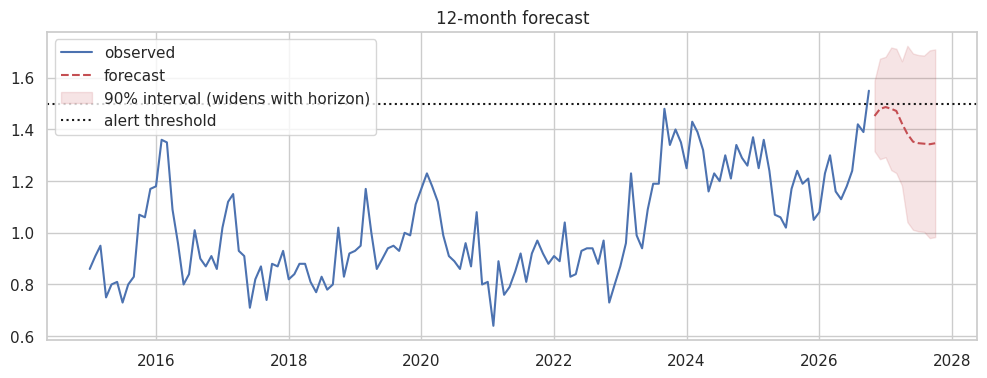

In [34]:
# ---- 12-month forecast beyond the last known month (fan chart: uncertainty widens with horizon) ----
fc = recursive_forecast(BEST, M_all, monthly, CONFIG['HORIZON'])
hz_half = HZ_HALF.reindex(range(1, CONFIG['HORIZON'] + 1)).ffill().bfill().values
forecast = pd.DataFrame({'forecast': fc.values, 'lower': fc.values - hz_half, 'upper': fc.values + hz_half}, index=fc.index)
display(forecast.round(3))
fig, ax = plt.subplots(figsize=(12, 4)); h_ = monthly.temp_anomaly.loc['2015':]
ax.plot(h_.index, h_, label='observed'); ax.plot(forecast.index, forecast.forecast, 'r--', label='forecast')
ax.fill_between(forecast.index, forecast.lower, forecast.upper, color='r', alpha=.15, label='90% interval (widens with horizon)')
ax.axhline(get_threshold(), color='k', ls=':', label='alert threshold'); ax.legend(); ax.set_title('12-month forecast'); plt.show()

## 17. Interactive dashboard (Plotly) + exports for Tableau

In [35]:
import plotly.graph_objects as go
fig = go.Figure()
h2 = monthly.temp_anomaly.loc['1990':]
fig.add_trace(go.Scatter(x=h2.index, y=h2, name='Observed', line=dict(color='#1f77b4', width=1)))
fig.add_trace(go.Scatter(x=h2.index, y=h2.rolling(12).mean(), name='12-month mean', line=dict(color='#ff7f0e', width=2)))
fig.add_trace(go.Scatter(x=idx_te, y=p_te, name='Test predictions', line=dict(color='green', dash='dot')))
fig.add_trace(go.Scatter(x=res_new.index, y=res_new.predicted, name='New-data predictions', line=dict(color='purple')))
fig.add_trace(go.Scatter(x=list(res_new.index) + list(res_new.index[::-1]), y=list(res_new.upper) + list(res_new.lower[::-1]), fill='toself', fillcolor='rgba(128,0,128,.15)', line=dict(width=0), name='90% interval', hoverinfo='skip'))
fig.add_trace(go.Scatter(x=forecast.index, y=forecast.forecast, name='12-month forecast', line=dict(color='red', dash='dash')))
fig.add_trace(go.Scatter(x=list(forecast.index) + list(forecast.index[::-1]), y=list(forecast.upper) + list(forecast.lower[::-1]), fill='toself', fillcolor='rgba(255,0,0,.12)', line=dict(width=0), name='forecast interval', hoverinfo='skip'))
if len(anomalies_real): fig.add_trace(go.Scatter(x=anomalies_real.index, y=monthly.temp_anomaly.loc[anomalies_real.index], mode='markers', name='Anomalies', marker=dict(color='black', size=9, symbol='x')))
fig.add_hline(y=get_threshold(), line_dash='dot', annotation_text='alert threshold')
fig.update_layout(title='EarthScape Climate Dashboard', xaxis=dict(rangeslider=dict(visible=True)), yaxis_title='Temperature anomaly (°C)', height=550, hovermode='x unified')
fig.write_html(f'{BASE}/outputs/dashboard.html'); fig.show()

# exports (import these CSVs into Tableau)
OUT = f'{BASE}/outputs'
monthly.to_csv(f'{OUT}/monthly_clean.csv')
pd.DataFrame({'actual': Y.loc[idx_te], 'predicted': p_te, 'lower': p_te - HALF, 'upper': p_te + HALF}).to_csv(f'{OUT}/test_predictions.csv')
res_new.to_csv(f'{OUT}/new_data_predictions.csv'); forecast.to_csv(f'{OUT}/forecast_12m.csv'); anomalies_real.to_csv(f'{OUT}/anomalies.csv')
corr_table.to_csv(f'{OUT}/correlation_table.csv', index=False); anom_scores.to_csv(f'{OUT}/anomaly_detection_scores.csv')
val_table.to_csv(f'{OUT}/metrics_validation.csv'); test_table.to_csv(f'{OUT}/metrics_test.csv'); new_scores.to_csv(f'{OUT}/metrics_new_data.csv'); hz.to_csv(f'{OUT}/metrics_by_horizon.csv')
print('Exported:', sorted(os.listdir(OUT)))

Exported: ['anomalies.csv', 'anomaly_detection_scores.csv', 'correlation_table.csv', 'dashboard.html', 'forecast_12m.csv', 'metrics_by_horizon.csv', 'metrics_new_data.csv', 'metrics_test.csv', 'metrics_validation.csv', 'monthly_clean.csv', 'new_data_predictions.csv', 'test_predictions.csv']


## 18. Reliability (backup), performance monitoring, final summary

Backup created: /content/drive/MyDrive/EarthScape/backups/backup_20261118_133134.zip (5.2 MB)
If Drive is not mounted, download this zip now (Files panel on the left → right-click → Download).


,stage,seconds,ram_mb,cpu_pct,at
7,horizon_backtest,53.195,1741.4,72.1,2026-11-18T13:30:53
3,tune_sklearn,48.042,418.9,95.7,2026-11-18T13:29:16
2,mapreduce_decades,38.006,358.8,76.3,2026-11-18T13:28:21
4,fit_lstm,17.894,1692.0,65.2,2026-11-18T13:29:40
8,anomaly_benchmark,8.489,1748.0,79.5,2026-11-18T13:31:02
6,fit_all,7.691,1722.0,0.0,2026-11-18T13:29:48
27,retrain,6.486,1810.3,48.0,2026-11-18T13:31:25
5,fit_lstm,6.342,1722.0,76.9,2026-11-18T13:29:48
26,fit_all,6.337,1810.0,0.0,2026-11-18T13:31:25
10,fit_all,6.193,1777.2,0.0,2026-11-18T13:31:11


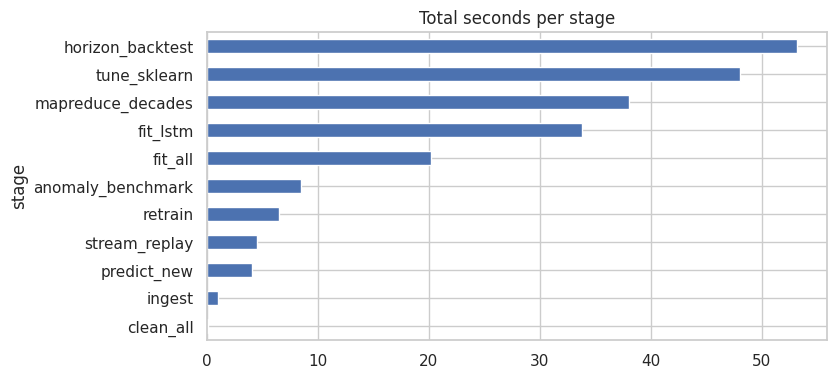

In [36]:
# ---- automated backup (zip of models + clean data + database) ----
def make_backup():
    ts = datetime.now().strftime('%Y%m%d_%H%M%S'); path = f'{BASE}/backups/backup_{ts}.zip'
    with zipfile.ZipFile(path, 'w', zipfile.ZIP_DEFLATED) as z:
        for folder in ['models', 'data/clean', 'db', 'outputs']:
            for root, _, files in os.walk(f'{BASE}/{folder}'):
                for f in files:
                    if f != 'secret.key': z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), BASE))
    return path
bk = make_backup(); print('Backup created:', bk, f'({os.path.getsize(bk) / 1e6:.1f} MB)')
print('If Drive is not mounted, download this zip now (Files panel on the left → right-click → Download).')

# ---- performance monitoring report ----
perf = pd.DataFrame(PERF); perf.to_csv(f'{BASE}/logs/performance_log.csv', index=False)
display(perf.sort_values('seconds', ascending=False).head(12))
perf.groupby('stage').seconds.sum().sort_values().plot.barh(figsize=(8, 4), title='Total seconds per stage'); plt.show()

In [37]:
print('=' * 70); print('FINAL SUMMARY'); print('=' * 70)
print(f'Production model         : {BEST}')
print(f'Test  RMSE / MAE / R²    : {test_table.loc[BEST, "RMSE"]:.3f} / {test_table.loc[BEST, "MAE"]:.3f} / {test_table.loc[BEST, "R2"]:.3f}')
print(f'Test  skill vs persistence: {test_table.loc[BEST, "Skill_vs_persistence"]:+.3f}  (>0 = better than "same as last month")')
print(f'NEW   RMSE / MAE         : {new_scores.iloc[0]["RMSE"]:.3f} / {new_scores.iloc[0]["MAE"]:.3f}  | interval coverage {res_new.in_interval.mean():.0%}')
print(f'Anomaly F1 (best method) : {anom_scores.F1.max():.2f} ({anom_scores.F1.idxmax()})')

FINAL SUMMARY
Production model         : Ensemble
Test  RMSE / MAE / R²    : 0.105 / 0.081 / 0.701
Test  skill vs persistence: +0.147  (>0 = better than "same as last month")
NEW   RMSE / MAE         : 0.112 / 0.094  | interval coverage 83%
Anomaly F1 (best method) : 0.84 (residual)


## ✅ Requirements checklist (where each requirement is satisfied)

| Requirement | Where |
|---|---|
| Authentication & role-based access (admin / analyst) | §12 PBKDF2 login, `PERMS`, `require()`, audit log |
| Ingestion: satellite-era / station / sensor-type data, historical **and** real-time, common formats | §1 (NASA, NOAA Mauna Loa, OWID; CSV/JSON-ready) + §15 streaming replay |
| Storage + partitioning (HDFS replacement) | §4 partitioned Parquet, partition-pruned reads |
| Parallel processing (MapReduce) | §5 PySpark map/reduceByKey (+ Spark SQL) |
| Patterns, anomalies, correlations, missing data | §3 cleaning, §6 EDA, §6.5 correlation + Granger, §11 anomalies |
| Real-time + batch integration | §15 |
| ML: trend prediction, anomaly detection, correlation | §10 (Ridge/RF/GB/Keras-LSTM/Ensemble), §11, §6.5 |
| Models regularly updated | §10.3 walk-forward, §16 `retrain()` with versioned saves |
| Interactive dashboards & visualisation | §17 Plotly + CSV exports for Tableau |
| Notifications & configurable alerts | §12 `alert_level`, DB-stored threshold (admin only), optional e-mail |
| Feedback & support | §12 `submit_feedback` / `read_feedback` |
| Performance monitoring + optimisation | §0 `@monitored`, §18 report |
| Data security (encryption, hashing) | §12 Fernet encryption, salted password hashes |
| Reliability (backup) | §18 `make_backup()` |
| Scalability | Parquet partitioning + Spark (scales to a cluster unchanged) |
| Evaluation metrics | §9-§10, §14: MAE, RMSE, R², Bias, MASE, Skill, DirAcc, coverage, P/R/F1 |
| Documentation / video | This notebook is the developer documentation; record your screen for the video demo |

**Assumptions for the ReadMe:** global-mean temperature anomaly is the target; CO₂ monthly data starts March 1958 so modelling starts 1959; Hadoop/Impala replaced by Parquet + PySpark/Pandas due to hardware limits and updated project requirements; demo passwords must be changed; no predictive model can foresee El Niño/volcanic shocks months ahead, which is why prediction intervals and per-horizon error are reported.

---
# 🚀 PART 2 — UPGRADES (purana code waisa hi hai; ye cells uske **baad** chalte hain)
Upar ka poora training/evaluation code **untouched** hai. Ye section sirf naye cheezein add karta hai, aur `Run all` se saari cells ek saath chal jaati hain.

| # | Kya add hua | Kis kami ko theek karta hai |
|---|---|---|
| 19 | ENSO (ONI), hemispheric series, **NetCDF gridded** data | SRS: diverse data / climate formats; model: ENSO missing |
| 20 | Feature ablation + recency weights + tuning | drift wale features (`trend12`, `co2_d12`), new-data skill |
| 21 | **Direct multi-horizon** models (h = 1…12) | 12-month forecast mein persistence se behtar nahi tha |
| 22 | Final honest scoring + intervals + 12-month forecast | test / new-data / coverage |
| 23 | **Impact model**: Arctic sea-ice extent | SRS: "trends **and impacts**" |
| 24 | Spike **quarantine** + duplicate-free alerts | streaming bug |
| 25 | Anomaly detection v2 (non-circular evaluation) | `robust_z` false positives, circular F1 |
| 26 | **Auto-retrain**: drift check → challenger → champion registry | "models regularly updated" |
| 27 | Extra Spark (MapReduce/SQL) jobs + Structured Streaming | sirf ek Spark job tha |
| 28 | Alert threshold justification | 1.5 °C baseline ka masla |
| 29 | Final comparison old vs new + backup | summary |

In [38]:
!pip install -q xarray netCDF4 h5netcdf

## 19. Extra data: ENSO (ONI), hemispheres, NetCDF grid
* **ONI** (Oceanic Niño Index, NOAA CPC): sabse bara driver of monthly global temperature. Hum ise **kam az kam 3 mahine ki lag** ke saath use karte hain (ONI 3-month average hai + publication delay) taake future leak na ho.
* **NH / SH** series (NASA GISTEMP): regional/hemispheric data.
* **NetCDF gridded** (NASA GISTEMP 2°×2° grid): climate-science ka standard format → area-weighted **climate zones** (Arctic, mid-latitudes, tropics, Antarctic). Isse "patterns" (Arctic amplification) bhi nikalte hain.

Agar koi download fail ho to cell crash nahi hoti, sirf wo hissa skip hota hai (aur message print hota hai).

ONI loaded from https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt: 1950-01 → 2026-09 (921 months)
ONI range now: 1950-01-01 → 2026-10-01
Warming rate since 1880 (°C/decade): {'NH': 0.1, 'SH': 0.068}


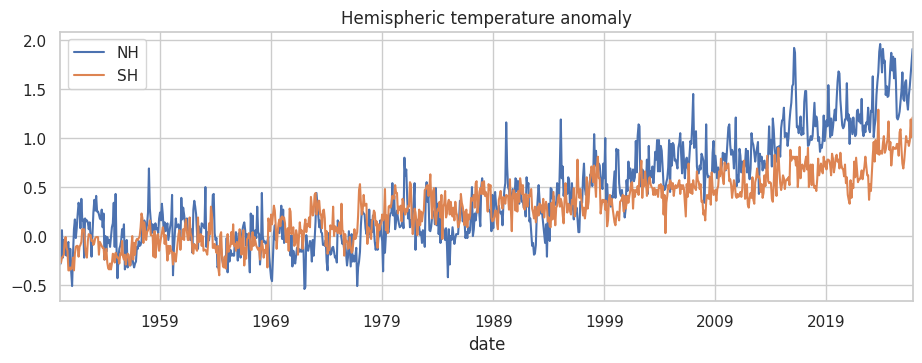

In [39]:
import io, gzip, urllib.request
from scipy import stats

UP = dict(
    ONI_URLS=['https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt'],
    ONI_PSL='https://psl.noaa.gov/data/correlation/oni.data',          # backup source
    ONI_LOCAL=None,                                                     # e.g. '/content/oni.ascii.txt' if you upload it manually
    NH_URL='https://data.giss.nasa.gov/gistemp/tabledata_v4/NH.Ts+dSST.csv',
    SH_URL='https://data.giss.nasa.gov/gistemp/tabledata_v4/SH.Ts+dSST.csv',
    NC_URL='https://data.giss.nasa.gov/pub/gistemp/gistemp1200_GHCNv4_ERSSTv5.nc.gz',
    ICE_URLS=['https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/data/N_{m:02d}_extent_v4.0.csv',
              'https://noaadata.apps.nsidc.org/NOAA/G02135/north/monthly/data/N_{m:02d}_extent_v3.0.csv'],
)
SEAS = ['DJF','JFM','FMA','MAM','AMJ','MJJ','JJA','JAS','ASO','SON','OND','NDJ']

def fetch_text(url, timeout=90):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0 (EarthScape student project)'})
    return urllib.request.urlopen(req, timeout=timeout).read().decode('utf-8', 'ignore')

def parse_oni_cpc(txt):
    rows = {}
    for ln in txt.splitlines():
        p = ln.split()
        if len(p) >= 4 and p[0] in SEAS:
            try: rows[pd.Timestamp(year=int(p[1]), month=SEAS.index(p[0]) + 1, day=1)] = float(p[3])
            except ValueError: pass
    return pd.Series(rows).sort_index()

def parse_oni_psl(txt):
    rows = {}
    for ln in txt.splitlines():
        p = ln.split()
        if len(p) == 13:
            try: y = int(p[0])
            except ValueError: continue
            for m, v in enumerate(p[1:], 1):
                v = float(v)
                if v > -90: rows[pd.Timestamp(year=y, month=m, day=1)] = v
    return pd.Series(rows).sort_index()

def load_oni():
    attempts = []
    if UP['ONI_LOCAL']: attempts.append(('local', lambda: parse_oni_cpc(open(UP['ONI_LOCAL']).read())))
    for u in UP['ONI_URLS']: attempts.append((u, lambda u=u: parse_oni_cpc(fetch_text(u))))
    attempts.append((UP['ONI_PSL'], lambda: parse_oni_psl(fetch_text(UP['ONI_PSL']))))
    for name, fn in attempts:
        try:
            s = fn()
            if len(s) > 500: print(f'ONI loaded from {name}: {s.index.min():%Y-%m} → {s.index.max():%Y-%m} ({len(s)} months)'); return s
        except Exception as e: print('  ONI source failed:', name, str(e)[:70])
    return None

oni_raw = load_oni()
USE_ENSO = oni_raw is not None
if USE_ENSO:
    oni_raw.to_csv(f'{BASE}/data/raw/noaa_oni.csv')
    ONI = oni_raw.reindex(monthly.index).ffill(limit=3)          # ffill only touches the last 1-3 not-yet-published months
    print('ONI range now:', ONI.dropna().index.min().date(), '→', ONI.dropna().index.max().date())
else:
    ONI = None
    print('⚠️ ONI not available → ENSO features are skipped (model still works). Upload oni.ascii.txt and set UP["ONI_LOCAL"].')

# ---- hemispheric series (same parsing as the global one) ----
def parse_giss_monthly(url):
    d = pd.read_csv(url, skiprows=1, na_values=['***', '****'])
    t = d[['Year'] + MONTHS].copy(); t['Year'] = pd.to_numeric(t['Year'], errors='coerce'); t = t.dropna(subset=['Year'])
    t = t.melt(id_vars='Year', var_name='mon', value_name='v'); t['v'] = pd.to_numeric(t['v'], errors='coerce')
    t['date'] = pd.to_datetime(dict(year=t.Year.astype(int), month=t['mon'].map({m: i + 1 for i, m in enumerate(MONTHS)}), day=1))
    return t.drop_duplicates('date').set_index('date').sort_index()['v'].dropna()

hemi = {}
for k, u in [('NH', UP['NH_URL']), ('SH', UP['SH_URL'])]:
    try: hemi[k] = parse_giss_monthly(u)
    except Exception as e: print(f'  {k} series skipped:', str(e)[:70])
if len(hemi) == 2:
    HEMI = pd.DataFrame(hemi).reindex(monthly.index)
    HEMI.to_csv(f'{BASE}/data/clean/hemispheres.csv')
    r = HEMI.dropna().apply(lambda c: np.polyfit(c.index.year + c.index.month / 12, c.values, 1)[0] * 10)
    print('Warming rate since 1880 (°C/decade):', r.round(3).to_dict())
    HEMI.loc['1950':].plot(figsize=(11, 3.5), title='Hemispheric temperature anomaly'); plt.show()

NetCDF dims: {'time': 1762, 'lat': 90, 'lon': 180} | time: 1880-01 → 2026-10

Warming rate 1980-2025 per climate zone (°C / decade)  (zonal pattern)
Arctic (65-90N)          0.656
N mid-lat (23.5-65N)     0.333
Tropics (23.5S-23.5N)    0.158
Antarctic (90-65S)       0.143
S mid-lat (65-23.5S)     0.094


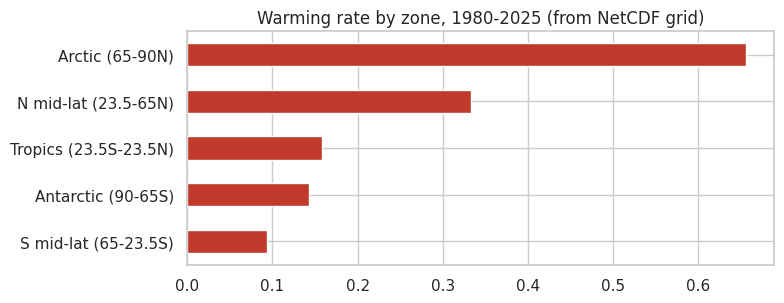

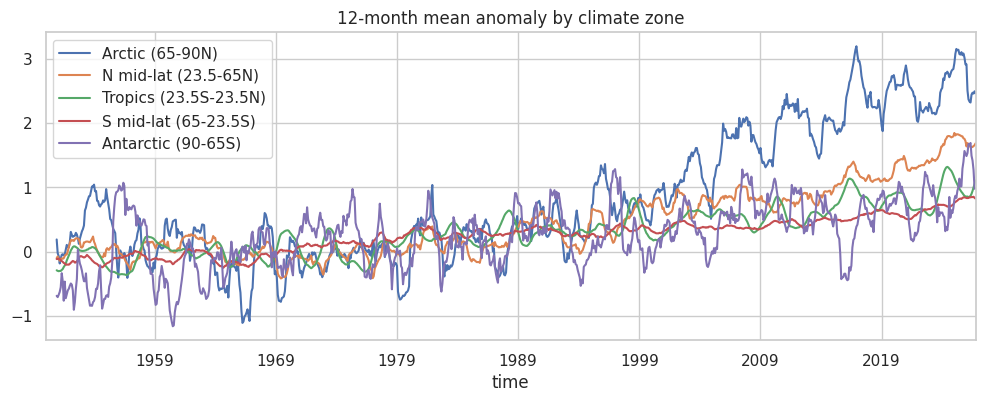

In [40]:
# ---- NetCDF gridded data → climate zones (satellite-era grid format used in climate science) ----
import xarray as xr
ZONES = {'Arctic (65-90N)': (65, 90), 'N mid-lat (23.5-65N)': (23.5, 65), 'Tropics (23.5S-23.5N)': (-23.5, 23.5),
         'S mid-lat (65-23.5S)': (-65, -23.5), 'Antarctic (90-65S)': (-90, -65)}
ZONAL = None
try:
    nc_gz, nc_path = f'{BASE}/data/raw/gistemp_grid.nc.gz', f'{BASE}/data/raw/gistemp_grid.nc'
    if not os.path.exists(nc_path):
        print('Downloading NetCDF grid (~50-100 MB) ...'); urllib.request.urlretrieve(UP['NC_URL'], nc_gz)
        with gzip.open(nc_gz, 'rb') as fi, open(nc_path, 'wb') as fo: shutil.copyfileobj(fi, fo)
    ds = xr.open_dataset(nc_path)
    da = ds['tempanomaly']
    print('NetCDF dims:', dict(da.sizes), '| time:', str(da.time.values[0])[:7], '→', str(da.time.values[-1])[:7])
    out = {}
    for name, (lo, hi) in ZONES.items():
        sub = da.where((da.lat >= lo) & (da.lat <= hi), drop=True)
        w = np.cos(np.deg2rad(sub.lat))
        s = sub.weighted(w).mean(('lat', 'lon')).to_series()
        s.index = pd.DatetimeIndex(s.index).to_period('M').to_timestamp(); out[name] = s
    ZONAL = pd.DataFrame(out).sort_index()
    ZONAL.to_csv(f'{BASE}/data/clean/climate_zones.csv')
    z_pq = f'{BASE}/data/parquet/zonal'; shutil.rmtree(z_pq, ignore_errors=True)
    ZONAL.rename_axis('date').reset_index().assign(year=lambda d: d.date.dt.year).to_parquet(z_pq, partition_cols=['year'], index=False)
    ann = ZONAL.groupby(ZONAL.index.year).mean().loc[1980:2025]
    rate = ann.apply(lambda c: np.polyfit(c.index, c.values, 1)[0] * 10).round(3)
    print('\nWarming rate 1980-2025 per climate zone (°C / decade)  (zonal pattern)'); print(rate.sort_values(ascending=False).to_string())
    ax = rate.sort_values().plot.barh(figsize=(8, 3.2), color='#c0392b'); ax.set_title('Warming rate by zone, 1980-2025 (from NetCDF grid)'); plt.tight_layout(); plt.show()
    ZONAL.loc['1950':].rolling(12).mean().plot(figsize=(12, 4), title='12-month mean anomaly by climate zone'); plt.show()
except Exception as e:
    print('⚠️ NetCDF part skipped:', str(e)[:150], '\n   (baaki sab chalega; link khud browser mein check kar lo ya file manually upload karke path set karo)')

## 20. Feature sets, ablation, recency weights, tuning
Pehle ki problem: new data par drift ke flags `trend12` aur `co2_d12` par aaye the (dono "trend" encode karte hain, jo har saal upar jaata hai). Yahan hum **data se** check karte hain:

* **A_old**: purane features (trend12 + co2_d12 ke saath)
* **B_no_drift**: unko hata kar
* **C_B+ENSO**: B + ONI (lag ≥ 3)
* **D_old+ENSO**: A + ONI

Phir **recency weighting** (recent saalon ko zyada weight) ko validation par test karte hain. Selection sirf **validation** par hota hai; test aur new data ko haath nahi lagate.

**Direct strategy:** horizon *h* ke liye alag model; target = `y[t] − base` jahan base = origin se pehle ke 12 mahine ka mean, aur features sirf `t−h` tak ki info use karte hain.

In [41]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit

HS_ALL = list(range(1, CONFIG['HORIZON'] + 1))
CORE  = ['dev_lag1', 'dev_lag2', 'dev_lag3', 'dev_lag6', 'dev_lag12', 'dev_roll3', 'dev_roll6', 'vol12']
TREND = ['trend12', 'co2_d12']
ENSO  = ['oni_l3', 'oni_l4', 'oni_l6', 'oni_chg']

def feats_generic(y, exog=None, exog_lags=(3, 4, 6), co2=None):
    """Row t uses ONLY information up to t-1 (exogenous series use lag >= 3 so they are really known)."""
    base = y.shift(1).rolling(12).mean(); f = pd.DataFrame({'base': base})
    for k in (1, 2, 3, 6, 12): f[f'dev_lag{k}'] = y.shift(k) - base
    f['dev_roll3'] = y.shift(1).rolling(3).mean() - base
    f['dev_roll6'] = y.shift(1).rolling(6).mean() - base
    f['vol12'] = y.shift(1).rolling(12).std()
    f['trend12'] = base - base.shift(12)
    if co2 is not None: f['co2_d12'] = co2.shift(1) - co2.shift(13)
    for name, s in (exog or {}).items():
        for L in exog_lags: f[f'{name}_l{L}'] = s.shift(L)
        f[f'{name}_chg'] = s.shift(3) - s.shift(6)
    return f

def direct_xy(F, cols, h):
    """Features for TARGET month t at horizon h come from the row that only knows data up to t-h."""
    s = h - 1
    X = F[cols].shift(s) if s else F[cols].copy(); b = F['base'].shift(s) if s else F['base'].copy()
    X = X.assign(m_sin=np.sin(2 * np.pi * X.index.month / 12), m_cos=np.cos(2 * np.pi * X.index.month / 12))   # season of the TARGET month
    return X, b

DEFAULT_P = dict(Ridge=dict(alpha=10), RF=dict(n=200, depth=5, leaf=3), GB=dict(n=150, lr=0.02))
def make_model(name, p):
    if name == 'Ridge': return Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=p['alpha']))])
    if name == 'RF': return RandomForestRegressor(n_estimators=p['n'], max_depth=p['depth'], min_samples_leaf=p['leaf'], random_state=SEED, n_jobs=-1)
    return GradientBoostingRegressor(n_estimators=p['n'], learning_rate=p['lr'], max_depth=2, subsample=0.8, random_state=SEED)

def recency_w(index, halflife):
    if not halflife: return None
    idx = pd.DatetimeIndex(index); months = (idx.max().year - idx.year) * 12 + (idx.max().month - idx.month)
    return 0.5 ** (np.asarray(months) / halflife)

def fit_one(est, X, y, w):
    if w is None: return est.fit(X, y)
    return est.fit(X, y, m__sample_weight=w) if isinstance(est, Pipeline) else est.fit(X, y, sample_weight=w)

def usable(X, b, y, idx):
    idx = pd.DatetimeIndex(idx); idx = idx[idx.isin(X.index)]
    ok = X.loc[idx].notna().all(axis=1) & b.loc[idx].notna() & y.reindex(idx).notna()
    return idx[ok.values]

def fit_direct(F, y, cols, idx_fit, hs, params=None, halflife=None, names=('Ridge', 'RF', 'GB')):
    params = params or DEFAULT_P; out = {}
    for h in hs:
        X, b = direct_xy(F, cols, h); ix = usable(X, b, y, idx_fit); w = recency_w(ix, halflife)
        out[h] = {n: fit_one(make_model(n, params[n]), X.loc[ix], (y.loc[ix] - b.loc[ix]), w) for n in names}
    return out

def predict_direct(F, cols, models, idx, h, require_y=None):
    X, b = direct_xy(F, cols, h); ix = usable(X, b, require_y if require_y is not None else pd.Series(1.0, index=X.index), idx)
    P = {n: pd.Series(b.loc[ix].values + m.predict(X.loc[ix]), index=ix) for n, m in models[h].items()}
    P['Ensemble'] = pd.concat(list(P.values()), axis=1).mean(axis=1)
    return P

def stat_row(yv, p, ref, m12):
    yv, p, ref, m12 = [np.asarray(a, float) for a in (yv, p, ref, m12)]; e = yv - p
    return dict(RMSE=np.sqrt(np.mean(e ** 2)), MAE=np.mean(np.abs(e)), R2=1 - np.sum(e ** 2) / np.sum((yv - yv.mean()) ** 2),
                Skill_vs_persistence=1 - np.sum(e ** 2) / np.sum((yv - ref) ** 2), Skill_vs_mean12=1 - np.sum(e ** 2) / np.sum((yv - m12) ** 2), n=len(yv))

def score_direct(F, y, cols, models, idx, hs, which=('Ensemble',)):
    rows = []
    for h in hs:
        P = predict_direct(F, cols, models, idx, h, require_y=y)
        for n in which:
            p = P[n]; ix = p.index
            rows.append(dict(h=h, model=n, **stat_row(y.loc[ix], p, y.shift(h).loc[ix], F['base'].shift(h - 1).loc[ix])))
    return pd.DataFrame(rows).set_index(['h', 'model'])

# ---- build the feature table for temperature ----
co2_f = monthly['co2_trend'].interpolate().ffill()
EXOG = {'oni': ONI} if USE_ENSO else None
F_T = feats_generic(Y, exog=EXOG, co2=co2_f)
ALL_T = Y.index[(Y.index >= pd.Timestamp('1960-01-01')) & Y.notna()]
n_new, n_te, n_va = CONFIG['NEW_MONTHS'], CONFIG['TEST_MONTHS'], CONFIG['VAL_MONTHS']
U_new, U_te = ALL_T[-n_new:], ALL_T[-(n_new + n_te):-n_new]
U_va, U_tr = ALL_T[-(n_new + n_te + n_va):-(n_new + n_te)], ALL_T[:-(n_new + n_te + n_va)]
print('Splits  train', U_tr.min().date(), '→', U_tr.max().date(), '| val', U_va.min().date(), '→', U_va.max().date(),
      '| test', U_te.min().date(), '→', U_te.max().date(), '| NEW', U_new.min().date(), '→', U_new.max().date())

FEATSETS = {'A_old (trend+co2)': CORE + TREND, 'B_no_drift': CORE}
if USE_ENSO: FEATSETS.update({'C_B+ENSO': CORE + ENSO, 'D_old+ENSO': CORE + TREND + ENSO})
HS_ABL = [1, 3, 6, 12]

Splits  train 1960-01-01 → 2009-10-01 | val 2009-11-01 → 2017-10-01 | test 2017-11-01 → 2025-10-01 | NEW 2025-11-01 → 2026-10-01


In [42]:
@monitored
def ablation():
    rows = []
    for nm, cols in FEATSETS.items():
        M = fit_direct(F_T, Y, cols, U_tr, HS_ABL)
        s = score_direct(F_T, Y, cols, M, U_va, HS_ABL)
        rows.append(dict(feature_set=nm, **{f'RMSE_h{h}': s.loc[(h, 'Ensemble'), 'RMSE'] for h in HS_ABL},
                         RMSE_mean=s['RMSE'].mean(), Skill_vs_persist_mean=s['Skill_vs_persistence'].mean()))
    return pd.DataFrame(rows).set_index('feature_set')

abl = ablation()
display(abl.round(4).style.set_caption('Feature ablation on VALIDATION (models trained on TRAIN only; lower RMSE = better)').background_gradient(subset=['RMSE_mean'], cmap='RdYlGn_r'))
BEST_SET = abl['RMSE_mean'].idxmin(); COLS = FEATSETS[BEST_SET]
print('➡ Best feature set on validation:', BEST_SET)
print('   Removing trend features helps?', 'YES' if abl.loc['B_no_drift', 'RMSE_mean'] < abl.loc['A_old (trend+co2)', 'RMSE_mean'] else 'NO')
if USE_ENSO: print('   Adding ENSO helps?', 'YES' if min(abl.loc['C_B+ENSO', 'RMSE_mean'], abl.loc['D_old+ENSO', 'RMSE_mean']) < min(abl.loc['A_old (trend+co2)', 'RMSE_mean'], abl.loc['B_no_drift', 'RMSE_mean']) else 'NO')

# ---- recency weighting (half-life in months) ----
rw = []
for hl in [None, 120, 240, 480]:
    M = fit_direct(F_T, Y, COLS, U_tr, HS_ABL, halflife=hl); s = score_direct(F_T, Y, COLS, M, U_va, HS_ABL)
    rw.append(dict(halflife_months=hl or 'none (equal weights)', RMSE_mean=s['RMSE'].mean(), Skill_vs_persist_mean=s['Skill_vs_persistence'].mean()))
rw = pd.DataFrame(rw).set_index('halflife_months'); display(rw.round(4).style.set_caption('Recency weighting on VALIDATION'))
HALFLIFE = {'none (equal weights)': None}.get(rw['RMSE_mean'].idxmin(), rw['RMSE_mean'].idxmin())
print('➡ Chosen half-life:', HALFLIFE)

,RMSE_h1,RMSE_h3,RMSE_h6,RMSE_h12,RMSE_mean,Skill_vs_persist_mean
feature_set,,,,,,
A_old (trend+co2),0.113900,0.147500,0.160600,0.162200,0.146100,0.224700
B_no_drift,0.112600,0.144100,0.154900,0.163700,0.143800,0.246300
C_B+ENSO,0.106200,0.136200,0.152500,0.160300,0.138800,0.301700
D_old+ENSO,0.107900,0.139300,0.154200,0.158600,0.140000,0.289400


➡ Best feature set on validation: C_B+ENSO
   Removing trend features helps? YES
   Adding ENSO helps? YES


,RMSE_mean,Skill_vs_persist_mean
halflife_months,,
none (equal weights),0.138800,0.301700
120,0.137100,0.317500
240,0.137300,0.315300
480,0.137900,0.309300


➡ Chosen half-life: 120


In [43]:
# ---- light hyper-parameter tuning (time-series CV inside TRAIN only; horizons 1, 6, 12 averaged) ----
GRIDS = {'Ridge': [dict(alpha=a) for a in (1, 10, 100, 1000)],
         'RF': [dict(n=200, depth=d, leaf=l) for d in (3, 5) for l in (3, 10)],
         'GB': [dict(n=n, lr=lr) for n in (100, 200) for lr in (0.02, 0.05)]}

@monitored
def tune_direct(cols, hs=(1, 6, 12), halflife=None):
    best = {}
    for name, grid in GRIDS.items():
        scores = []
        for p in grid:
            errs = []
            for h in hs:
                X, b = direct_xy(F_T, cols, h); ix = usable(X, b, Y, U_tr); Xi, di = X.loc[ix], (Y.loc[ix] - b.loc[ix])
                for tr, te in TimeSeriesSplit(n_splits=4).split(Xi):
                    w = recency_w(Xi.index[tr], halflife); m = fit_one(make_model(name, p), Xi.iloc[tr], di.iloc[tr], w)
                    errs.append(np.sqrt(np.mean((di.iloc[te] - m.predict(Xi.iloc[te])) ** 2)))
            scores.append(np.mean(errs))
        best[name] = grid[int(np.argmin(scores))]; print(f'{name:6s} best={best[name]}  CV-RMSE={min(scores):.4f}')
    return best

BEST_P = tune_direct(COLS, halflife=HALFLIFE)
M_chk = fit_direct(F_T, Y, COLS, U_tr, HS_ABL, BEST_P, HALFLIFE); s_chk = score_direct(F_T, Y, COLS, M_chk, U_va, HS_ABL)
print(f'Validation mean RMSE  default params: {abl.loc[BEST_SET, "RMSE_mean"]:.4f}  →  tuned: {s_chk["RMSE"].mean():.4f}')
if s_chk['RMSE'].mean() > abl.loc[BEST_SET, 'RMSE_mean']: BEST_P = DEFAULT_P; print('Tuned params not better on validation → keeping defaults.')

Ridge  best={'alpha': 10}  CV-RMSE=0.1417
RF     best={'n': 200, 'depth': 3, 'leaf': 10}  CV-RMSE=0.1466
GB     best={'n': 100, 'lr': 0.02}  CV-RMSE=0.1459
Validation mean RMSE  default params: 0.1388  →  tuned: 0.1377


## 21–22. Direct multi-horizon models: honest scoring + prediction intervals + 12-month forecast
Protocol (bilkul purane jaisa, no leakage):
1. models **Train** par fit → **Validation** par error → interval width (90% quantile) har horizon ke liye
2. **Train+Val** par fit → **Test** par ek final score
3. **Train+Val+Test** par fit (= production) → **New (unseen 12 months)** par score + coverage
4. Poore data par fit → asli 12-month forecast

In [44]:
@monitored
def full_protocol():
    M_a = fit_direct(F_T, Y, COLS, U_tr, HS_ALL, BEST_P, HALFLIFE)                       # train only
    half = {}
    for h in HS_ALL:
        p = predict_direct(F_T, COLS, M_a, U_va, h, require_y=Y)['Ensemble']; half[h] = float(np.quantile(np.abs(Y.loc[p.index] - p), CONFIG['INTERVAL']))
    half = pd.Series(half).cummax()                                                       # uncertainty never shrinks with horizon
    M_b = fit_direct(F_T, Y, COLS, U_tr.append(U_va), HS_ALL, BEST_P, HALFLIFE)           # train + val
    sc_te = score_direct(F_T, Y, COLS, M_b, U_te, HS_ALL, which=('Ridge', 'RF', 'GB', 'Ensemble'))
    M_c = fit_direct(F_T, Y, COLS, U_tr.append(U_va).append(U_te), HS_ALL, BEST_P, HALFLIFE)   # production
    sc_new = score_direct(F_T, Y, COLS, M_c, U_new, HS_ALL)
    cov = {}
    for nm, M_, idx in [('test', M_b, U_te), ('new', M_c, U_new)]:
        cov[nm] = {h: float((np.abs(Y.loc[(p := predict_direct(F_T, COLS, M_, idx, h, require_y=Y)['Ensemble']).index] - p) <= half[h]).mean()) for h in HS_ALL}
    return M_a, M_b, M_c, half, sc_te, sc_new, cov

DM_tr, DM_trva, DM_prod, HALF_H, sc_te2, sc_new2, COV = full_protocol()
tab = sc_te2.xs('Ensemble', level='model')[['RMSE', 'MAE', 'R2', 'Skill_vs_persistence', 'Skill_vs_mean12']].copy()
tab['coverage_test'] = pd.Series(COV['test']); tab['half_width'] = HALF_H
display(tab.round(3).style.set_caption('TEST, direct models (Ensemble) per horizon').background_gradient(subset=['Skill_vs_persistence'], cmap='RdYlGn'))
tabn = sc_new2.xs('Ensemble', level='model')[['RMSE', 'MAE', 'Skill_vs_persistence', 'n']].copy(); tabn['coverage_new'] = pd.Series(COV['new'])
display(tabn.round(3).style.set_caption('UNSEEN NEW 12 months, production models (small n → read with care)'))
print(f'Mean skill vs persistence on TEST over h=1..12: {tab.Skill_vs_persistence.mean():+.3f}  | horizons beating persistence: {(tab.Skill_vs_persistence > 0).sum()}/12')
print(f'Mean coverage  TEST: {np.mean(list(COV["test"].values())):.1%}  | NEW: {np.mean(list(COV["new"].values())):.1%}  (target {CONFIG["INTERVAL"]:.0%})')

# ---- per-model comparison at selected horizons ----
cmp = sc_te2.loc[[1, 3, 6, 12], ['RMSE', 'Skill_vs_persistence']].unstack('model').round(3)
display(cmp.style.set_caption('Which model wins? (TEST)'))

,RMSE,MAE,R2,Skill_vs_persistence,Skill_vs_mean12,coverage_test,half_width
h,,,,,,,
1,0.101000,0.078000,0.721000,0.204000,0.465000,0.906000,0.166000
2,0.114000,0.086000,0.648000,0.226000,0.409000,0.906000,0.206000
3,0.130000,0.094000,0.541000,0.252000,0.318000,0.906000,0.232000
4,0.141000,0.102000,0.464000,0.219000,0.279000,0.885000,0.233000
5,0.152000,0.114000,0.374000,0.144000,0.227000,0.875000,0.233000
6,0.159000,0.117000,0.312000,0.135000,0.216000,0.865000,0.233000
7,0.166000,0.122000,0.255000,0.160000,0.207000,0.854000,0.233000
8,0.170000,0.127000,0.215000,0.195000,0.212000,0.865000,0.234000
9,0.173000,0.127000,0.185000,0.244000,0.224000,0.896000,0.247000


,RMSE,MAE,Skill_vs_persistence,n,coverage_new
h,,,,,
1,0.088000,0.070000,0.335000,12,1.000000
2,0.096000,0.081000,0.579000,12,1.000000
3,0.121000,0.094000,0.532000,12,1.000000
4,0.131000,0.098000,0.454000,12,0.917000
5,0.150000,0.119000,0.123000,12,0.917000
6,0.169000,0.141000,-0.243000,12,0.750000
7,0.183000,0.153000,-0.283000,12,0.667000
8,0.201000,0.166000,0.062000,12,0.667000
9,0.201000,0.167000,0.209000,12,0.583000


Mean skill vs persistence on TEST over h=1..12: +0.213  | horizons beating persistence: 12/12
Mean coverage  TEST: 87.8%  | NEW: 81.2%  (target 90%)


,forecast,lower,upper
2026-11-01,1.501,1.335,1.667
2026-12-01,1.540,1.334,1.747
2027-01-01,1.527,1.295,1.758
2027-02-01,1.496,1.263,1.729
2027-03-01,1.476,1.242,1.709
2027-04-01,1.393,1.160,1.626
2027-05-01,1.356,1.123,1.589
2027-06-01,1.345,1.111,1.580
2027-07-01,1.348,1.101,1.594
2027-08-01,1.332,1.079,1.585


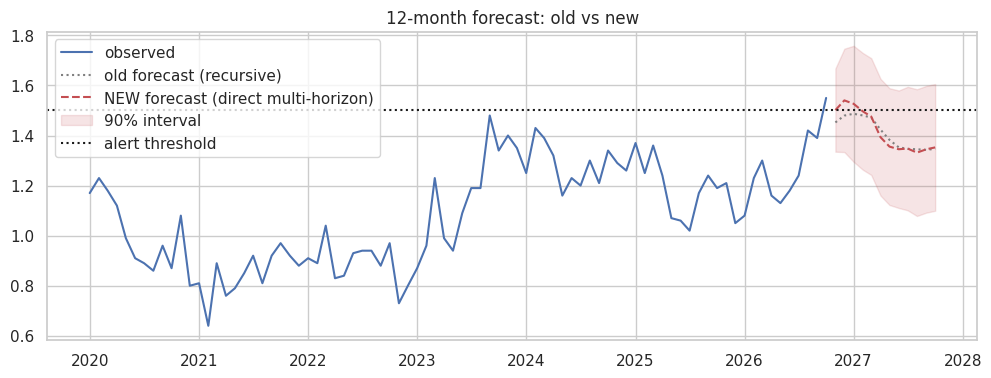

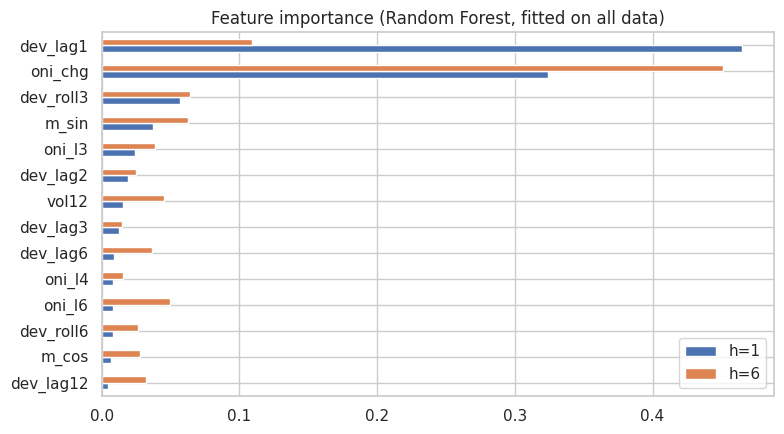

In [45]:
# ---- final fit on ALL data → real 12-month forecast (fan chart) ----
@monitored
def make_forecast(cols, params, halflife, half):
    ALLIDX = Y.dropna().index[Y.dropna().index >= pd.Timestamp('1960-01-01')]
    DM_all = fit_direct(F_T, Y, cols, ALLIDX, HS_ALL, params, halflife)
    last = Y.dropna().index[-1]; fut = pd.date_range(last + pd.offsets.MonthBegin(1), periods=CONFIG['HORIZON'], freq='MS')
    ext = Y.reindex(Y.index.append(fut)); ex = {'oni': ONI.reindex(ext.index).ffill(limit=15)} if USE_ENSO else None
    F_ext = feats_generic(ext, exog=ex, co2=co2_f.reindex(ext.index).ffill())
    fc = []
    for h in HS_ALL:
        X, b = direct_xy(F_ext, cols, h); t = fut[h - 1]
        row = X.loc[[t]]
        if row.isna().any(axis=None): raise ValueError(f'Forecast features missing for {t:%Y-%m}: {row.columns[row.isna().any()].tolist()}')
        fc.append(float(b.loc[t] + np.mean([m.predict(row)[0] for m in DM_all[h].values()])))
    out = pd.DataFrame({'forecast': fc}, index=fut); out['lower'] = out.forecast - half.reindex(HS_ALL).values; out['upper'] = out.forecast + half.reindex(HS_ALL).values
    return out, DM_all

forecast2, DM_all = make_forecast(COLS, BEST_P, HALFLIFE, HALF_H)
display(forecast2.round(3))
fig, ax = plt.subplots(figsize=(12, 4)); h_ = Y.loc['2020':]
ax.plot(h_.index, h_, label='observed')
if 'forecast' in globals(): ax.plot(forecast.index, forecast.forecast, color='grey', ls=':', label='old forecast (recursive)')
ax.plot(forecast2.index, forecast2.forecast, 'r--', label='NEW forecast (direct multi-horizon)')
ax.fill_between(forecast2.index, forecast2.lower, forecast2.upper, color='r', alpha=.15, label='90% interval')
ax.axhline(get_threshold(), color='k', ls=':', label='alert threshold'); ax.legend(); ax.set_title('12-month forecast: old vs new'); plt.show()

# ---- what drives the forecast? (feature importance of the h=1 and h=6 RandomForest) ----
X1, _ = direct_xy(F_T, COLS, 1); X6, _ = direct_xy(F_T, COLS, 6)
imp = pd.DataFrame({'h=1': pd.Series(DM_all[1]['RF'].feature_importances_, index=X1.columns), 'h=6': pd.Series(DM_all[6]['RF'].feature_importances_, index=X6.columns)}).sort_values('h=1')
imp.plot.barh(figsize=(8, 4.5), title='Feature importance (Random Forest, fitted on all data)'); plt.tight_layout(); plt.show()

## 23. Impact model: Arctic sea-ice extent (NSIDC)
SRS sirf temperature nahi, **"climate trends and impacts"** maangta hai. Arctic sea-ice extent ek seedha climate **impact** hai. Same leakage-free direct-multi-horizon machinery use hoti hai; features: sea-ice ki apni history + **global temperature** (impact ka driver) + month. Target = extent ka **anomaly** (month ki climatology train period se nikali jaati hai).

In [46]:
def load_seaice():
    frames = []
    for m in range(1, 13):
        got = None
        for tmpl in UP['ICE_URLS']:
            try:
                d = pd.read_csv(io.StringIO(fetch_text(tmpl.format(m=m))), skipinitialspace=True)
                d.columns = [c.strip().lower() for c in d.columns]; got = d[['year', 'mo', 'extent']]; break
            except Exception as e: err = str(e)[:60]
        if got is None: raise RuntimeError(f'month {m}: {err}')
        frames.append(got)
    d = pd.concat(frames); d = d[d.extent > 0]
    s = pd.Series(d.extent.values, index=pd.to_datetime(dict(year=d.year.astype(int), month=d.mo.astype(int), day=1))).sort_index()
    return s.asfreq('MS').interpolate(limit=3)

ICE = None
try:
    ICE = load_seaice(); ICE.to_csv(f'{BASE}/data/raw/nsidc_arctic_extent.csv')
    print(f'Arctic sea-ice extent loaded: {ICE.index.min():%Y-%m} → {ICE.index.max():%Y-%m}  ({len(ICE)} months, million km²)')
except Exception as e:
    print('⚠️ Sea-ice download failed → impact model skipped:', str(e)[:120], '\n   (upload the CSVs / change UP["ICE_URLS"] and re-run this cell)')

Arctic sea-ice extent loaded: 1978-11 → 2026-10  (576 months, million km²)


,RMSE,MAE,R2,Skill_vs_persistence,Skill_vs_mean12
h,,,,,
1,0.249000,0.205000,0.684000,0.530000,0.694000
3,0.369000,0.301000,0.307000,0.685000,0.378000
6,0.362000,0.307000,0.333000,0.788000,0.439000
12,0.331000,0.279000,0.442000,0.420000,0.591000


,,RMSE,Skill_vs_persistence,n
h,model,,,
1,Ensemble,0.128000,0.521000,12
3,Ensemble,0.212000,0.644000,12
6,Ensemble,0.186000,0.878000,12
12,Ensemble,0.342000,-1.108000,12


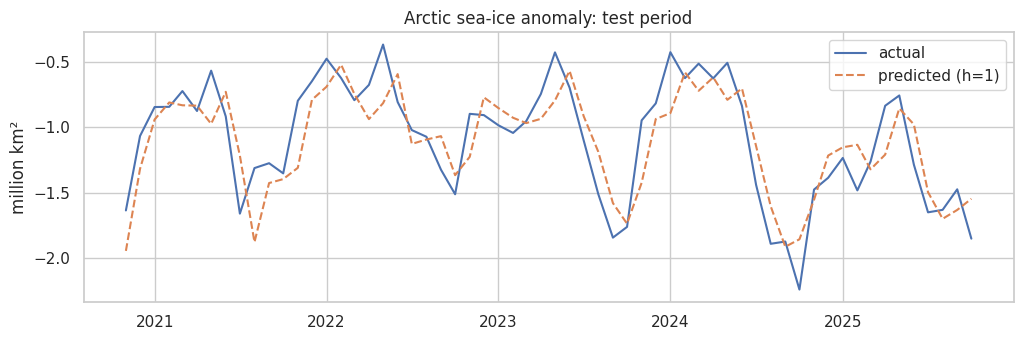

Correlation ice-anomaly vs 12-mo global temp: levels -0.82  |  month-to-month changes -0.03


In [47]:
@monitored
def impact_model():
    ice = ICE.loc['1979':].dropna(); ice = ice.asfreq('MS')
    ice_dates = ice.index[(ice.index >= pd.Timestamp('1981-01-01'))]
    i_new, i_te = ice_dates[-12:], ice_dates[-72:-12]; i_va, i_tr = ice_dates[-132:-72], ice_dates[:-132]
    clim = ice.loc[:i_tr[-1]].groupby(ice.loc[:i_tr[-1]].index.month).mean()                 # climatology from TRAIN period only
    anom = ice - clim.reindex(ice.index.month).values
    F_I = feats_generic(anom, exog={'gt': Y.rolling(12).mean().reindex(anom.index)}, exog_lags=(1, 3))
    cols_i = CORE + ['gt_l1', 'gt_l3', 'gt_chg']; hs = [1, 3, 6, 12]
    M1 = fit_direct(F_I, anom, cols_i, i_tr, hs); s_va = score_direct(F_I, anom, cols_i, M1, i_va, hs)
    M2 = fit_direct(F_I, anom, cols_i, i_tr.append(i_va), hs); s_te = score_direct(F_I, anom, cols_i, M2, i_te, hs, which=('Ridge', 'RF', 'GB', 'Ensemble'))
    M3 = fit_direct(F_I, anom, cols_i, i_tr.append(i_va).append(i_te), hs); s_new = score_direct(F_I, anom, cols_i, M3, i_new, hs)
    return anom, F_I, cols_i, M2, i_te, i_new, s_va, s_te, s_new, clim

if ICE is not None:
    ice_anom, F_I, cols_i, M_ice, i_te, i_new, s_va_i, s_te_i, s_new_i, ice_clim = impact_model()
    display(s_te_i.xs('Ensemble', level='model')[['RMSE', 'MAE', 'R2', 'Skill_vs_persistence', 'Skill_vs_mean12']].round(3).style.set_caption('IMPACT MODEL (sea-ice anomaly, million km²) — TEST'))
    display(s_new_i[['RMSE', 'Skill_vs_persistence', 'n']].round(3).style.set_caption('IMPACT MODEL — unseen last 12 months'))
    p1 = predict_direct(F_I, cols_i, M_ice, i_te, 1, require_y=ice_anom)['Ensemble']
    fig, ax = plt.subplots(figsize=(12, 3.5)); ax.plot(p1.index, ice_anom.loc[p1.index], label='actual'); ax.plot(p1.index, p1, '--', label='predicted (h=1)')
    ax.set_title('Arctic sea-ice anomaly: test period'); ax.set_ylabel('million km²'); ax.legend(); plt.show()
    # impact ↔ temperature correlation (honest: levels vs de-trended)
    j = pd.concat([ice_anom.rename('ice'), Y.rolling(12).mean().rename('gt')], axis=1).dropna().loc['1981':]
    print(f'Correlation ice-anomaly vs 12-mo global temp: levels {j.corr().iloc[0, 1]:+.2f}  |  month-to-month changes {j.diff().corr().iloc[0, 1]:+.2f}')

## 24. Streaming fix: spike **quarantine** + duplicate-free alerts
Pehle bug: sensor spike (2.06 °C) alert to deta tha, lekin history mein ghus kar agle mahine ki prediction kharab kar deta tha (1.44 vs actual 1.13).
Ab: agar `|z| > QUARANTINE_Z` ho to alert **phir bhi** jata hai, lekin history mein **predicted value** jaati hai (reading "quarantined" mark hoti hai). Real garam mahine (jaise 1.55 °C, z≈1.4) quarantine nahi hote, kyunke rule absolute value par nahi, **surprise (z)** par hai.
Saath mein `log_alert_once`: same `(month, level)` DB mein dobara nahi jaata → notebook baar baar chalane se duplicates nahi banenge.

In [48]:
QUARANTINE_Z = 4.0

def log_alert_once(month, value, level, message):
    m = str(month)[:7]
    with db() as c: dup = c.execute('SELECT 1 FROM alerts WHERE month=? AND level=?', (m, level)).fetchone()
    if not dup: log_alert(month, value, level, message)

@monitored
def predict_new2(new_df, state=None, log=False, quarantine_z=QUARANTINE_Z):
    S = state or STATE; d = validate_new(new_df); hist = S['hist'].copy(); rows = []
    expected = hist.index[-1] + pd.offsets.MonthBegin(1)
    if d.index[0] != expected: raise ValueError(f'New data must start at {expected.date()} (got {d.index[0].date()}); no gaps allowed.')
    for dt, r in d.iterrows():
        co2 = r.co2_trend if pd.notna(r.co2_trend) else float(extend_co2(hist.co2_trend.interpolate().ffill().values, 1)[0])
        hist.loc[dt] = [np.nan, co2]
        yhat = float(predict(S['best'], S['M'], hist, [dt]).iloc[0])
        imputed = pd.isna(r.temp_anomaly); actual = yhat if imputed else float(r.temp_anomaly)
        z = np.nan if imputed else (actual - yhat) / S['sigma']
        level = alert_level(actual, z)
        quarantined = (not imputed) and abs(z) > quarantine_z
        hist.loc[dt, 'temp_anomaly'] = yhat if quarantined else actual            # ← bad reading never poisons the history
        rows.append(dict(month=dt, actual=actual, predicted=yhat, lower=yhat - S['half'], upper=yhat + S['half'],
                         error=np.nan if imputed else actual - yhat, in_interval=np.nan if imputed else abs(actual - yhat) <= S['half'],
                         z=z, level=level, imputed=imputed, quarantined=quarantined))
        if log and level != 'OK':
            log_alert_once(dt, actual, level, f'{level}: {dt:%Y-%m} anomaly {actual:+.2f}°C (model expected {yhat:+.2f}, z={z:+.1f})' + (' [QUARANTINED]' if quarantined else ''))
    return pd.DataFrame(rows).set_index('month'), hist

@monitored
def stream_replay2(new_df, delay=0.1, spike_at=None, spike=0.9, quarantine=True):
    S = dict(STATE); S['hist'] = STATE['hist'].copy(); out = []
    for i, (dt, r) in enumerate(new_df.iterrows()):
        row = r.copy()
        if spike_at == i: row['temp_anomaly'] += spike; print('   💥 simulated sensor spike injected')
        res, S['hist'] = predict_new2(pd.DataFrame([row.values], index=[dt], columns=new_df.columns), state=S, log=True, quarantine_z=QUARANTINE_Z if quarantine else 1e9)
        x = res.iloc[0]; out.append(res)
        print(f'{dt:%Y-%m}  actual={x.actual:+.2f}  pred={x.predicted:+.2f}  z={x.z:+.1f}  → {x.level}' + ('   ⛔ quarantined (history keeps predicted value)' if x.quarantined else ''))
        time.sleep(delay)
    return pd.concat(out), S['hist']

print('--- OLD behaviour (spike stays in history) ---'); s_old, _ = stream_replay2(new_in, spike_at=5, quarantine=False, delay=0)
print('\n--- NEW behaviour (spike quarantined) ---');       s_new, hist_q = stream_replay2(new_in, spike_at=5, quarantine=True, delay=0)
nxt = s_old.index[6]
print(f'\nMonth after the spike ({nxt:%Y-%m}): actual={s_old.actual[nxt]:+.2f} | old prediction={s_old.predicted[nxt]:+.2f} (err {s_old.predicted[nxt]-s_old.actual[nxt]:+.2f}) | new prediction={s_new.predicted[nxt]:+.2f} (err {s_new.predicted[nxt]-s_new.actual[nxt]:+.2f})')
s_new.to_csv(f'{BASE}/data/stream/stream_log_v2.csv'); serving = hist_q
with db() as c: print('Alerts table rows:', c.execute('SELECT COUNT(*) FROM alerts').fetchone()[0], '(no duplicates for same month+level)')

--- OLD behaviour (spike stays in history) ---
2025-11  actual=+1.21  pred=+1.20  z=+0.1  → OK
2025-12  actual=+1.05  pred=+1.21  z=-1.4  → OK
2026-01  actual=+1.08  pred=+1.16  z=-0.7  → OK
2026-02  actual=+1.23  pred=+1.12  z=+0.9  → OK
2026-03  actual=+1.30  pred=+1.18  z=+1.1  → OK
   💥 simulated sensor spike injected
2026-04  actual=+2.06  pred=+1.21  z=+7.4  → CRITICAL
2026-05  actual=+1.13  pred=+1.44  z=-2.7  → OK
2026-06  actual=+1.18  pred=+1.29  z=-1.0  → OK
2026-07  actual=+1.24  pred=+1.22  z=+0.2  → OK
2026-08  actual=+1.42  pred=+1.26  z=+1.4  → WARNING
2026-09  actual=+1.39  pred=+1.36  z=+0.2  → WARNING
2026-10  actual=+1.55  pred=+1.39  z=+1.4  → CRITICAL

--- NEW behaviour (spike quarantined) ---
2025-11  actual=+1.21  pred=+1.20  z=+0.1  → OK
2025-12  actual=+1.05  pred=+1.21  z=-1.4  → OK
2026-01  actual=+1.08  pred=+1.16  z=-0.7  → OK
2026-02  actual=+1.23  pred=+1.12  z=+0.9  → OK
2026-03  actual=+1.30  pred=+1.18  z=+1.1  → OK
   💥 simulated sensor spike injecte

## 25. Anomaly detection v2 (non-circular evaluation)
Problems in v1: (1) injected anomalies σ ke multiples mein the aur residual detector usi σ par bana tha → **circular** F1; (2) `robust_z` 24-month median use karta tha jo trend ke saath chalta nahi → 2023 ke kai mahine false positive.
v2: `robust_z2` ab **deviation-from-base** par hai (trend hata hua, stationary); injected sizes **absolute °C** mein (0.2 / 0.3 / 0.4 / 0.6) taake dikhe ki kitna chhota anomaly pakda ja sakta hai; plus real-data check.

In [49]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_fscore_support

H1_MODELS = DM_trva                                       # direct models trained on Train+Val (honest for the test period)
res_v = []
for _p in [predict_direct(F_T, COLS, DM_tr, U_va, 1, require_y=Y)['Ensemble']]: res_v = Y.loc[_p.index] - _p
SIG2 = float(1.4826 * np.median(np.abs(res_v - np.median(res_v))))
print(f'Robust σ of one-step error (validation) = {SIG2:.3f} °C')

def robust_z2(y, F, win=120):
    dev = (y - F['base']); prev = dev.shift(1)
    med = prev.rolling(win, min_periods=60).median()
    mad = prev.rolling(win, min_periods=60).apply(lambda a: np.median(np.abs(a - np.median(a))), raw=True) * 1.4826
    return (dev - med) / mad

def iso_X(F, y): return pd.DataFrame({'d1': F['dev_lag1'], 'd2': F['dev_lag2'], 'vol': F['vol12'], 'cur': y - F['base']})
ISO2 = IsolationForest(n_estimators=300, contamination=0.02, random_state=SEED).fit(iso_X(F_T, Y).loc[U_tr].dropna())

def detect2(y_series, idx, models=H1_MODELS, Z=CONFIG['ANOMALY_Z']):
    Fq = feats_generic(y_series, exog=EXOG, co2=co2_f); o = pd.DataFrame(index=pd.DatetimeIndex(idx))
    p = predict_direct(Fq, COLS, models, o.index, 1, require_y=y_series)['Ensemble'].reindex(o.index)
    o['resid_z'] = (y_series.loc[o.index] - p) / SIG2; o['robust_z2'] = robust_z2(y_series, Fq).loc[o.index]
    X = iso_X(Fq, y_series).loc[o.index]; o['iso'] = np.where(X.notna().all(axis=1), ISO2.predict(X.fillna(0)) == -1, False)
    o['flag_residual'] = o.resid_z.abs() > Z; o['flag_robust2'] = o.robust_z2.abs() > Z; o['flag_iso'] = o.iso.astype(bool)
    o['flag_vote'] = o[['flag_residual', 'flag_robust2', 'flag_iso']].sum(axis=1) >= 2
    o['flag_either'] = o.flag_residual | o.flag_robust2
    return o

@monitored
def anomaly_benchmark2(trials=10, mags=(0.2, 0.3, 0.4, 0.6), frac=0.06):
    rows = []
    for s in range(trials):
        for mg in mags:
            rng = np.random.default_rng(SEED + s); d = Y.copy(); lab = pd.Series(False, index=U_te)
            for dt in rng.choice(U_te, int(len(U_te) * frac), replace=False): d.loc[dt] += rng.choice([-1, 1]) * mg; lab[dt] = True
            det = detect2(d, U_te)
            for m in ['flag_residual', 'flag_robust2', 'flag_iso', 'flag_vote', 'flag_either']:
                pr, rc, f1, _ = precision_recall_fscore_support(lab, det[m].reindex(lab.index).fillna(False), average='binary', zero_division=0)
                rows.append(dict(magnitude_C=mg, method=m.replace('flag_', ''), precision=pr, recall=rc, F1=f1))
    return pd.DataFrame(rows).groupby(['method', 'magnitude_C']).mean().round(3)

an2 = anomaly_benchmark2()
display(an2['F1'].unstack('magnitude_C').style.set_caption('F1 by injected anomaly size (°C) — absolute sizes, not σ-multiples').background_gradient(cmap='RdYlGn', axis=None))
display(an2['recall'].unstack('magnitude_C').style.set_caption('Recall by anomaly size'))
real2 = detect2(Y, U_te.append(U_new))
print('\nREAL data (test + new 12 months), months flagged:')
for m in ['flag_residual', 'flag_robust2', 'flag_iso']: print(f'  {m:15s}: {int(real2[m].sum()):2d} → {[d.strftime("%Y-%m") for d in real2.index[real2[m]]]}')
print('Compare: old robust_z flagged 8 months in 2023 alone. If robust2 flags far fewer, the false-positive problem is fixed.')
anomalies_real2 = real2[real2[['flag_residual', 'flag_robust2']].any(axis=1)][['resid_z', 'robust_z2']].round(2); anomalies_real2.to_csv(f'{OUT}/anomalies_v2.csv'); anom_scores2 = an2; an2.to_csv(f'{OUT}/anomaly_detection_scores_v2.csv')

Robust σ of one-step error (validation) = 0.119 °C


magnitude_C,0.200000,0.300000,0.400000,0.600000
method,,,,
either,0.239000,0.455000,0.760000,0.857000
iso,0.131000,0.173000,0.228000,0.261000
residual,0.119000,0.454000,0.799000,0.929000
robust2,0.239000,0.412000,0.669000,0.846000
vote,0.164000,0.380000,0.722000,0.865000


magnitude_C,0.200000,0.300000,0.400000,0.600000
method,,,,
either,0.180000,0.400000,0.800000,1.000000
iso,0.140000,0.240000,0.380000,0.560000
residual,0.080000,0.360000,0.760000,1.000000
robust2,0.180000,0.360000,0.660000,0.940000
vote,0.120000,0.320000,0.700000,1.000000



REAL data (test + new 12 months), months flagged:
  flag_residual  :  1 → ['2023-09']
  flag_robust2   :  2 → ['2023-09', '2026-10']
  flag_iso       :  4 → ['2023-09', '2023-10', '2023-11', '2023-12']
Compare: old robust_z flagged 8 months in 2023 alone. If robust2 flags far fewer, the false-positive problem is fixed.


## 26. Automatic re-training: drift check → challenger → champion registry
SRS: *"Regularly update and refine models based on the latest data"*. Pehle `retrain()` sirf manual function tha. Ab pipeline:

1. **New data aaya?** (champion ke `trained_until` ke baad)
2. **Drift check**: KS-test (features) + recent error vs validation error
3. **Challenger** = naya model, recent **6 months chhod kar** train; champion aur challenger dono ko **same 6 months** par score karo
4. Challenger ≥ champion → **promote** (phir saare data par refit, naya version save, `registry.json` update). Warna champion hi rehta hai.

Har decision registry mein likha jaata hai (audit trail).

In [50]:
REG_PATH = f'{BASE}/models/registry.json'
def reg_load(): return json.load(open(REG_PATH)) if os.path.exists(REG_PATH) else dict(versions=[], champion=None)
def reg_save(r): json.dump(r, open(REG_PATH, 'w'), indent=2, default=str)

def save_direct(dep, tag, extra):
    d = f'{BASE}/models/{tag}'; os.makedirs(d, exist_ok=True)
    pickle.dump(dep, open(f'{d}/direct_models.pkl', 'wb')); json.dump(extra, open(f'{d}/metadata.json', 'w'), indent=2, default=str); return d
def load_direct(d): return pickle.load(open(f'{d}/direct_models.pkl', 'rb'))

def make_deployment(models, trained_until):
    return dict(models=models, cols=COLS, params=BEST_P, halflife=HALFLIFE, half=HALF_H.to_dict(), trained_until=str(trained_until.date()), hs=HS_ALL)

DEPLOY = make_deployment(DM_prod, U_te[-1])                      # champion = production model (trained before the unseen months)
V = 'v3_direct_' + datetime.now().strftime('%Y%m%d_%H%M'); d3 = save_direct(DEPLOY, V, dict(created=datetime.now().isoformat(timespec='seconds'), feature_set=BEST_SET, cols=COLS, halflife=HALFLIFE, params=BEST_P, trained_until=DEPLOY['trained_until'], role='initial champion'))
REG = reg_load(); REG['versions'].append(dict(version=V, created=datetime.now().isoformat(timespec='seconds'), trained_until=DEPLOY['trained_until'], decision='initial champion'))
REG['champion'] = V; reg_save(REG)
chk = load_direct(d3); a_ = predict_direct(F_T, COLS, DM_prod, U_new, 1, require_y=Y)['Ensemble']; b_ = predict_direct(F_T, COLS, chk['models'], U_new, 1, require_y=Y)['Ensemble']
print('Saved →', d3, '| reloaded model gives identical predictions:', bool(np.allclose(a_.values, b_.values)))

Saved → /content/drive/MyDrive/EarthScape/models/v3_direct_20261118_1335 | reloaded model gives identical predictions: True


In [51]:
from scipy.stats import ks_2samp

def drift_check(F, cols, ref_idx, recent_idx, champ_recent_rmse=None, base_rmse=None):
    rows = []
    for c in cols:
        a, b = F.loc[ref_idx, c].dropna(), F.loc[recent_idx, c].dropna()
        if len(a) > 20 and len(b) > 5: k = ks_2samp(a, b); rows.append(dict(feature=c, KS=round(k.statistic, 3), p=round(k.pvalue, 4), drift=k.pvalue < 0.01))
    t = pd.DataFrame(rows); n = int(t.drift.sum()) if len(t) else 0
    ratio = (champ_recent_rmse / base_rmse) if (champ_recent_rmse and base_rmse) else np.nan
    return t, n, ratio, (n >= 2) or (pd.notna(ratio) and ratio > 1.25)

EVAL_M = 6
@monitored
def maybe_retrain(force=False, verbose=True):
    global DEPLOY, F_T
    REG = reg_load(); trained_until = pd.Timestamp(DEPLOY['trained_until']); last = Y.dropna().index[-1]
    new_months = int(((last.year - trained_until.year) * 12 + last.month - trained_until.month))
    ALLT = Y.dropna().index[Y.dropna().index >= pd.Timestamp('1960-01-01')]; ev = ALLT[-EVAL_M:]; pre = ALLT[:-EVAL_M]
    ch = score_direct(F_T, Y, DEPLOY['cols'], DEPLOY['models'], ev, [1, 3, 6]); champ_rmse = ch['RMSE'].mean()
    base_rmse = float(tab.loc[[1, 3, 6], 'RMSE'].mean())                                                    # validation-era error level
    drift_tab, n_drift, ratio, drift = drift_check(F_T, DEPLOY['cols'], U_tr, ALLT[-24:], champ_rmse, base_rmse)
    if verbose:
        print(f'New months since champion: {new_months} | drifting features: {n_drift} | recent/validation error ratio: {ratio:.2f} → drift={drift}')
        if len(drift_tab): display(drift_tab.set_index('feature').T)
    if new_months <= 0 and not force: print('No new data → nothing to do.'); return None
    if not (drift or force or new_months >= 12): print('No drift and < 12 new months → keep champion.'); return None
    chal = fit_direct(F_T, Y, DEPLOY['cols'], pre, [1, 3, 6], DEPLOY['params'], DEPLOY['halflife'])           # challenger never sees the last 6 months
    cs = score_direct(F_T, Y, DEPLOY['cols'], chal, ev, [1, 3, 6]); chal_rmse = cs['RMSE'].mean()
    promote = chal_rmse <= champ_rmse
    print(f'Last {EVAL_M} months, mean RMSE over h=1,3,6 → champion {champ_rmse:.4f} | challenger {chal_rmse:.4f} → {"PROMOTE challenger" if promote else "KEEP champion"}')
    entry = dict(created=datetime.now().isoformat(timespec='seconds'), champion_rmse=round(champ_rmse, 4), challenger_rmse=round(chal_rmse, 4), drift=bool(drift), new_months=new_months)
    if promote:
        full = fit_direct(F_T, Y, DEPLOY['cols'], ALLT, HS_ALL, DEPLOY['params'], DEPLOY['halflife'])           # then refit on ALL data
        DEPLOY = make_deployment(full, last); tag = 'v3_direct_' + datetime.now().strftime('%Y%m%d_%H%M%S')
        save_direct(DEPLOY, tag, dict(**entry, trained_until=DEPLOY['trained_until'], cols=DEPLOY['cols'])); entry.update(version=tag, decision='promoted', trained_until=DEPLOY['trained_until']); REG['champion'] = tag
    else: entry.update(version=REG['champion'], decision='kept champion')
    REG['versions'].append(entry); reg_save(REG); return entry

decision = maybe_retrain()
print('\nRegistry:'); display(pd.DataFrame(reg_load()['versions']).tail(5))

New months since champion: 12 | drifting features: 0 | recent/validation error ratio: 1.06 → drift=False


feature,dev_lag1,dev_lag2,dev_lag3,dev_lag6,dev_lag12,dev_roll3,dev_roll6,vol12,oni_l3,oni_l4,oni_l6,oni_chg
KS,0.131,0.128,0.17,0.122,0.22,0.175,0.261,0.284,0.267,0.305,0.313,0.166
p,0.7721,0.7975,0.4648,0.8382,0.1819,0.4305,0.071,0.0382,0.0614,0.0213,0.0166,0.4994
drift,False,False,False,False,False,False,False,False,False,False,False,False


Last 6 months, mean RMSE over h=1,3,6 → champion 0.1379 | challenger 0.1391 → KEEP champion

Registry:


,version,created,trained_until,decision,champion_rmse,challenger_rmse,drift,new_months
0,v3_direct_20261118_1335,2026-11-18T13:35:28,2025-10-01,initial champion,NaN,NaN,NaN,NaN
1,v3_direct_20261118_1335,2026-11-18T13:35:31,NaN,kept champion,0.1379,0.1391,False,12.0


## 27. More Spark: extra MapReduce / SQL jobs + Structured Streaming
Pehle sirf ek Spark job tha (decade average). Ab teen aur jobs + ek **real streaming** demo: nayi readings JSON files ki tarah folder mein girti hain aur Spark Structured Streaming unhe padhta hai aur alert level lagata hai. (Agar Spark kisi wajah se na chale to Pandas fallback chalta hai, crash nahi hota.)

In [52]:
@monitored
def spark_jobs_extra():
    try:
        from pyspark.sql import SparkSession, functions as Fn
        spark = SparkSession.builder.master('local[*]').appName('EarthScape2').config('spark.ui.showConsoleProgress', 'false').getOrCreate(); spark.sparkContext.setLogLevel('ERROR')
        sdf = spark.read.parquet(pq_dir)
        rdd = sdf.select('year', 'temp_anomaly').rdd.filter(lambda r: r.temp_anomaly is not None)
        hot = (rdd.map(lambda r: ((r.year // 10) * 10, (1 if r.temp_anomaly > 1.0 else 0, 1)))                    # MAP
                  .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))                                           # REDUCE
                  .mapValues(lambda v: round(100 * v[0] / v[1], 1)).sortByKey().collect())
        corr = sdf.filter('year >= 1959').select(Fn.corr('temp_anomaly', 'co2_trend')).first()[0]                 # job 2: correlation in Spark SQL
        sdf.createOrReplaceTempView('m2')
        slope = spark.sql("""SELECT covar_samp(year, a)/var_samp(year) AS s FROM (SELECT year, AVG(temp_anomaly) a FROM m2 WHERE year BETWEEN 1980 AND 2025 GROUP BY year)""").first()[0]
        return pd.Series(dict(hot), name='% months above +1.0°C'), corr, slope * 10, 'PySpark'
    except Exception as e:
        print('Spark unavailable → Pandas fallback:', str(e)[:80])
        h = (monthly.temp_anomaly > 1.0).groupby((monthly.index.year // 10) * 10).mean().mul(100).round(1)
        d = monthly.loc['1959':]; ann_ = monthly.temp_anomaly.groupby(monthly.index.year).mean().loc[1980:2025]
        return h, d.temp_anomaly.corr(d.co2_trend), np.polyfit(ann_.index, ann_.values, 1)[0] * 10, 'Pandas fallback'

hot, corr_sp, slope_sp, eng = spark_jobs_extra()
print(f'Engine: {eng}\nJob 1 (MapReduce): share of months above +1.0 °C per decade'); display(hot.to_frame())
print(f'Job 2 (Spark SQL corr): temperature vs CO2 trend since 1959 = {corr_sp:.3f}\nJob 3 (Spark SQL regression slope): warming 1980-2025 = {slope_sp:.3f} °C per decade')

Engine: PySpark
Job 1 (MapReduce): share of months above +1.0 °C per decade


,% months above +1.0°C
1880,0.0
1890,0.0
1900,0.0
1910,0.0
1920,0.0
1930,0.0
1940,0.0
1950,0.0
1960,0.0
1970,0.0


Job 2 (Spark SQL corr): temperature vs CO2 trend since 1959 = 0.931
Job 3 (Spark SQL regression slope): warming 1980-2025 = 0.208 °C per decade


In [53]:
@monitored
def spark_streaming_demo(new_df):
    inc = f'{BASE}/data/stream/incoming'; shutil.rmtree(inc, ignore_errors=True); os.makedirs(inc)
    for i, (dt, r) in enumerate(new_df.iterrows()):
        json.dump({'month': dt.strftime('%Y-%m-%d'), 'temp_anomaly': float(r.temp_anomaly)}, open(f'{inc}/reading_{i:03d}.json', 'w'))
    seen = []
    try:
        from pyspark.sql import SparkSession
        spark = SparkSession.builder.master('local[*]').appName('EarthScapeStream').config('spark.ui.showConsoleProgress', 'false').getOrCreate(); spark.sparkContext.setLogLevel('ERROR')
        def handle(batch_df, batch_id):
            for _, x in batch_df.toPandas().sort_values('month').iterrows(): seen.append((x.month[:7], x.temp_anomaly, alert_level(float(x.temp_anomaly), np.nan)))
        q = (spark.readStream.schema('month STRING, temp_anomaly DOUBLE').json(inc).writeStream.foreachBatch(handle).trigger(availableNow=True).start())
        q.awaitTermination(); eng = 'Spark Structured Streaming'
    except Exception as e:
        print('Structured Streaming unavailable → plain file loop:', str(e)[:80]); eng = 'file-loop fallback'
        for f in sorted(os.listdir(inc)):
            x = json.load(open(f'{inc}/{f}')); seen.append((x['month'][:7], x['temp_anomaly'], alert_level(x['temp_anomaly'], np.nan)))
    return pd.DataFrame(seen, columns=['month', 'temp_anomaly', 'level']), eng

stream_spark, eng_s = spark_streaming_demo(new_in)
print('Engine:', eng_s, '| readings processed:', len(stream_spark)); display(stream_spark)

Engine: Spark Structured Streaming | readings processed: 12


,month,temp_anomaly,level
0,2025-11,1.21,OK
1,2025-12,1.05,OK
2,2026-01,1.08,OK
3,2026-02,1.23,OK
4,2026-03,1.30,OK
5,2026-04,1.16,OK
6,2026-05,1.13,OK
7,2026-06,1.18,OK
8,2026-07,1.24,OK
9,2026-08,1.42,WARNING


## 28. Alert threshold: baseline ka masla
GISTEMP anomalies **1951–1980** ke against hain, jabke Paris Agreement ka "1.5 °C" **pre-industrial** (≈1880-1899) ke against hai. Dono alag zero-points hain. Neeche exact conversion nikalti hai taake report mein threshold ko justify kar sako.

In [54]:
pre = monthly.temp_anomaly.loc['1880':'1899'].mean()
paris_on_this_baseline = 1.5 + pre
print(f'Pre-industrial (1880-1899) level in the 1951-80 baseline = {pre:+.2f} °C')
print(f'→ "1.5 °C above pre-industrial" = +{paris_on_this_baseline:.2f} °C on THIS dataset\'s scale')
print(f'→ your current ALERT_THRESHOLD = {get_threshold():.2f} °C here = {get_threshold() - pre:.2f} °C above pre-industrial')
print(f'Share of last 12 months above current threshold: {(Y.iloc[-12:] >= get_threshold()).mean():.0%} | above Paris-equivalent: {(Y.iloc[-12:] >= paris_on_this_baseline).mean():.0%}')
print('Decision for the report: either keep the threshold as an admin-configurable operational value (state it clearly), or set it to the Paris-equivalent via set_threshold(adm, X).')

Pre-industrial (1880-1899) level in the 1951-80 baseline = -0.23 °C
→ "1.5 °C above pre-industrial" = +1.27 °C on THIS dataset's scale
→ your current ALERT_THRESHOLD = 1.50 °C here = 1.73 °C above pre-industrial
Share of last 12 months above current threshold: 8% | above Paris-equivalent: 33%
Decision for the report: either keep the threshold as an admin-configurable operational value (state it clearly), or set it to the Paris-equivalent via set_threshold(adm, X).


## 29. Final comparison: old vs new + backup

In [55]:
rows = []
for h in HS_ALL:
    r = dict(h=h, RMSE_new_direct=tab.loc[h, 'RMSE'], Skill_new=tab.loc[h, 'Skill_vs_persistence'])
    if 'hz' in globals() and h in hz.index: r.update(RMSE_old_recursive=hz.loc[h, 'RMSE_model'], RMSE_persistence_old_eval=hz.loc[h, 'RMSE_persistence'])
    rows.append(r)
final_cmp = pd.DataFrame(rows).set_index('h'); display(final_cmp.round(3).style.set_caption('Per-horizon error: old (recursive) vs new (direct). Protocols differ slightly (old: origins every 3 months), so compare the trend, not the 3rd decimal.'))
final_cmp.to_csv(f'{OUT}/horizon_comparison_old_vs_new.csv'); tab.to_csv(f'{OUT}/metrics_test_direct.csv'); tabn.to_csv(f'{OUT}/metrics_new_direct.csv'); forecast2.to_csv(f'{OUT}/forecast_12m_v2.csv')
if ZONAL is not None: ZONAL.to_csv(f'{OUT}/climate_zones.csv')

print('=' * 74); print('UPGRADE SUMMARY'); print('=' * 74)
print(f'Feature set chosen (validation)     : {BEST_SET} | recency half-life: {HALFLIFE}')
print(f'ENSO used                           : {USE_ENSO}')
old_beats = int((hz.RMSE_model < hz.RMSE_persistence).sum()) if 'hz' in globals() else None
print(f'Horizons beating persistence (TEST) : {(tab.Skill_vs_persistence > 0).sum()}/12   (old recursive model, section 10.4 table: {old_beats}/12)')
print(f'h=1 TEST RMSE / skill               : {tab.loc[1, "RMSE"]:.3f} / {tab.loc[1, "Skill_vs_persistence"]:+.3f}')
print(f'NEW-data h=1 skill / mean coverage  : {tabn.loc[1, "Skill_vs_persistence"]:+.3f} / {np.mean(list(COV["new"].values())):.0%}')
if ICE is not None: print(f'Impact model (sea-ice) h=1 skill    : {s_te_i.loc[(1, "Ensemble"), "Skill_vs_persistence"]:+.3f} (TEST)')
print(f'Champion model version              : {reg_load()["champion"]}')
bk2 = make_backup(); print('Backup (incl. new models + registry):', bk2)

,RMSE_new_direct,Skill_new,RMSE_old_recursive,RMSE_persistence_old_eval
h,,,,
1,0.101000,0.204000,0.100000,0.105000
2,0.114000,0.226000,0.138000,0.132000
3,0.130000,0.252000,0.119000,0.109000
4,0.141000,0.219000,0.131000,0.126000
5,0.152000,0.144000,0.161000,0.151000
6,0.159000,0.135000,0.150000,0.147000
7,0.166000,0.160000,0.173000,0.166000
8,0.170000,0.195000,0.199000,0.201000
9,0.173000,0.244000,0.176000,0.178000


UPGRADE SUMMARY
Feature set chosen (validation)     : C_B+ENSO | recency half-life: 120
ENSO used                           : True
Horizons beating persistence (TEST) : 12/12   (old recursive model, section 10.4 table: 4/12)
h=1 TEST RMSE / skill               : 0.101 / +0.204
NEW-data h=1 skill / mean coverage  : +0.335 / 81%
Impact model (sea-ice) h=1 skill    : +0.530 (TEST)
Champion model version              : v3_direct_20261118_1335
Backup (incl. new models + registry): /content/drive/MyDrive/EarthScape/backups/backup_20261118_133545.zip


## ✅ Updated requirements checklist (Part 2)

| Requirement | Where |
|---|---|
| Diverse datasets + common climate formats (station/satellite-era/grid) | §19: ONI, NH/SH, **NetCDF** gridded zones (+ §1 originals) |
| Patterns (not only trend) | §19 climate-zone warming rates (Arctic amplification), §6 EDA |
| Parallel processing / MapReduce / SQL | §5 + §27 (3 more Spark jobs) |
| Real-time streaming integrated with batch | §15 + §24 (quarantine) + §27 (Spark Structured Streaming) |
| ML: trend prediction | §21–22 direct multi-horizon models, §10 originals |
| ML: **impacts** | §23 Arctic sea-ice model |
| ML: anomaly detection | §25 v2 (+ §11 original) |
| ML: correlation | §6.5, §23, §27 |
| **Regular model update** | §26 drift check → challenger → champion registry |
| Alerts | §12 + §24 (no duplicates) + §28 threshold justification |